In [1]:
import pandas as pd
import numpy as np
import re
from pathlib import Path

In [2]:
sample_log = """
2026-08-25 10:15:01.125 | LTE | RRC | Connection Request | UE=1001
2026-08-25 10:15:02.310 | LTE | RRC | Connection Setup | UE=1001
2026-08-25 10:15:03.020 | LTE | NAS | Registration Request | UE=1001
2026-08-25 10:15:04.145 | LTE | NAS | Authentication Request | UE=1001
2026-08-25 10:15:05.280 | LTE | NAS | Authentication Failure | UE=1001 | Cause=21
2026-08-25 10:15:06.010 | LTE | RRC | Connection Release | UE=1001 | Cause=3
2026-08-25 10:16:01.100 | NR | RRC | Registration Request | UE=1002
2026-08-25 10:16:02.225 | NR | RRC | Reconfiguration | UE=1002
2026-08-25 10:16:03.450 | NR | RRC | Measurement Report | UE=1002
2026-08-25 10:16:04.775 | NR | RRC | Handover Command | UE=1002
2026-08-25 10:16:05.900 | NR | RRC | Handover Failure | UE=1002 | Cause=HO_TIMEOUT
2026-08-25 10:16:06.125 | NR | RRC | Connection Release | UE=1002 | Cause=HO_FAILURE
2026-08-25 10:17:01.050 | LTE | MAC | UL Retransmission | UE=1003 | Count=8
2026-08-25 10:17:02.110 | LTE | RLC | DL Retransmission | UE=1003 | Count=12
2026-08-25 10:17:03.250 | LTE | NAS | Registration Accept | UE=1003
2026-08-25 10:18:01.300 | NR | NAS | Registration Request | UE=1004
2026-08-25 10:18:02.410 | NR | NAS | Authentication Request | UE=1004
2026-08-25 10:18:03.520 | NR | NAS | Authentication Response | UE=1004
2026-08-25 10:18:04.650 | NR | NAS | Registration Accept | UE=1004
2026-08-25 10:19:01.020 | LTE | RRC | Connection Request | UE=1005
2026-08-25 10:19:02.130 | LTE | RRC | Connection Setup | UE=1005
2026-08-25 10:19:03.240 | LTE | NAS | Registration Reject | UE=1005 | Cause=15
2026-08-25 10:19:04.350 | LTE | RRC | Connection Release | UE=1005 | Cause=3
"""

with open("sample_qxdm.log", "w") as file:
    file.write(sample_log.strip())

print("Sample QXDM-style log created successfully!")

Sample QXDM-style log created successfully!


In [3]:
with open("sample_qxdm.log", "r") as file:
    logs = file.readlines()

for log in logs[:4]:
    print(log.strip())

2026-08-25 10:15:01.125 | LTE | RRC | Connection Request | UE=1001
2026-08-25 10:15:02.310 | LTE | RRC | Connection Setup | UE=1001
2026-08-25 10:15:03.020 | LTE | NAS | Registration Request | UE=1001
2026-08-25 10:15:04.145 | LTE | NAS | Authentication Request | UE=1001


In [4]:
import pandas as pd


In [5]:
with open("sample_qxdm.log", "r") as file:
    logs = file.readlines()

print("Total log lines:", len(logs))

Total log lines: 23


In [6]:
print(logs[6])

2026-08-25 10:16:01.100 | NR | RRC | Registration Request | UE=1002



In [7]:
#split the log understand how split will work?
line=logs[6].strip()

parts=line.split("|")

print(parts)


['2026-08-25 10:16:01.100 ', ' NR ', ' RRC ', ' Registration Request ', ' UE=1002']


In [8]:
line = logs[4].strip()

parts = line.split("|")

print(parts)

['2026-08-25 10:15:05.280 ', ' LTE ', ' NAS ', ' Authentication Failure ', ' UE=1001 ', ' Cause=21']


In [9]:
timestamp = parts[0].strip()
rat = parts[1].strip()
protocol = parts[2].strip()
event = parts[3].strip()
ue = parts[4].strip()
cause = parts[5].strip()

print(timestamp)
print(rat)
print(protocol)
print(event)
print(ue)
print(cause)

2026-08-25 10:15:05.280
LTE
NAS
Authentication Failure
UE=1001
Cause=21


In [10]:
ue_id = ue.split("=")[1]

print(ue_id)

cause_value = cause.split("=")[1]

print(cause_value)

1001
21


In [11]:
record = {
    "timestamp": timestamp,
    "rat": rat,
    "protocol": protocol,
    "event": event,
    "ue_id": ue_id,
    "cause": cause_value
}

print(record)

{'timestamp': '2026-08-25 10:15:05.280', 'rat': 'LTE', 'protocol': 'NAS', 'event': 'Authentication Failure', 'ue_id': '1001', 'cause': '21'}


In [12]:
#Now parse ALL log lines
records = []

for line in logs:

    line = line.strip()

    if not line:
        continue

    parts = line.split("|")

    timestamp = parts[0].strip()
    rat = parts[1].strip()
    protocol = parts[2].strip()
    event = parts[3].strip()

    ue = parts[4].strip()
    ue_id = ue.split("=")[1]

    cause = None

    if len(parts) > 5:
        cause = parts[5].strip().split("=")[1]

    record = {
        "timestamp": timestamp,
        "rat": rat,
        "protocol": protocol,
        "event": event,
        "ue_id": ue_id,
        "cause": cause
    }

    records.append(record)

print("Total parsed records:", len(records))

Total parsed records: 23


In [13]:
df=pd.DataFrame(records)
df.head()

,timestamp,rat,protocol,event,ue_id,cause
0,2026-08-25 10:15:01.125,LTE,RRC,Connection Request,1001,None
1,2026-08-25 10:15:02.310,LTE,RRC,Connection Setup,1001,None
2,2026-08-25 10:15:03.020,LTE,NAS,Registration Request,1001,None
3,2026-08-25 10:15:04.145,LTE,NAS,Authentication Request,1001,None
4,2026-08-25 10:15:05.280,LTE,NAS,Authentication Failure,1001,21


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   timestamp  23 non-null     object
 1   rat        23 non-null     object
 2   protocol   23 non-null     object
 3   event      23 non-null     object
 4   ue_id      23 non-null     object
 5   cause      8 non-null      object
dtypes: object(6)
memory usage: 1.2+ KB


In [15]:
df.sample()

,timestamp,rat,protocol,event,ue_id,cause
15,2026-08-25 10:18:01.300,NR,NAS,Registration Request,1004,None


In [16]:
df["protocol"].value_counts()

,count
protocol,
RRC,12
NAS,9
MAC,1
RLC,1


In [17]:
df["rat"].value_counts()

,count
rat,
LTE,13
NR,10


"The raw modem logs were semi-structured text with a delimiter-based format. I first read the logs line-by-line and used the pipe delimiter to separate timestamp, RAT, protocol, event and additional parameters. I then extracted key-value fields such as UE ID and cause code, stored each parsed event as a dictionary, and finally converted the collection of dictionaries into a Pandas DataFrame for downstream analysis and feature engineering."

"The DataFrame gives us a structured representation of the logs and makes filtering, grouping, aggregation, feature engineering and ML preprocessing much easier."

Make the parser robust

We'll add:

try/except
malformed-line handling
optional fields
Regex
automatic event classification
is_failure
severity
proper timestamp datatype
numeric UE/cause fields

In [18]:
def parse_log_line(line):

    line = line.strip()

    if not line:
        return None

    parts = line.split("|")

    # We need at least 5 fields
    if len(parts) < 5:
        print("Skipping invalid line:", line)
        return None

    timestamp = parts[0].strip()
    rat = parts[1].strip()
    protocol = parts[2].strip()
    event = parts[3].strip()

    ue_field = parts[4].strip()

    # Check UE format
    if "=" not in ue_field:
        print("Invalid UE field:", line)
        return None

    ue_id = ue_field.split("=", 1)[1]

    cause = None
    count = None

    # Process optional fields
    for field in parts[5:]:
        field = field.strip()

        if "=" not in field:
            continue

        key, value = field.split("=", 1)

        key = key.strip()
        value = value.strip()

        if key.lower() == "cause":
            cause = value

        elif key.lower() == "count":
            count = value

    return {
        "timestamp": timestamp,
        "rat": rat,
        "protocol": protocol,
        "event": event,
        "ue_id": ue_id,
        "cause": cause,
        "count": count
    }

In [19]:
line = logs[4]

result = parse_log_line(line)

print(result)

{'timestamp': '2026-08-25 10:15:05.280', 'rat': 'LTE', 'protocol': 'NAS', 'event': 'Authentication Failure', 'ue_id': '1001', 'cause': '21', 'count': None}


In [20]:
#Test a retransmission event
line = logs[12]

result = parse_log_line(line)

print(result)

{'timestamp': '2026-08-25 10:17:01.050', 'rat': 'LTE', 'protocol': 'MAC', 'event': 'UL Retransmission', 'ue_id': '1003', 'cause': None, 'count': '8'}


In [21]:
records = []

for line in logs:

    result = parse_log_line(line)

    if result is not None:
        records.append(result)

print("Successfully parsed:", len(records))

Successfully parsed: 23


In [22]:
df = pd.DataFrame(records)

df.head()

,timestamp,rat,protocol,event,ue_id,cause,count
0,2026-08-25 10:15:01.125,LTE,RRC,Connection Request,1001,None,None
1,2026-08-25 10:15:02.310,LTE,RRC,Connection Setup,1001,None,None
2,2026-08-25 10:15:03.020,LTE,NAS,Registration Request,1001,None,None
3,2026-08-25 10:15:04.145,LTE,NAS,Authentication Request,1001,None,None
4,2026-08-25 10:15:05.280,LTE,NAS,Authentication Failure,1001,21,None


In [23]:
#Convert data types
df["timestamp"] = pd.to_datetime(df["timestamp"])

df["ue_id"] = pd.to_numeric(
    df["ue_id"],
    errors="coerce"
)

df["count"] = pd.to_numeric(
    df["count"],
    errors="coerce"
)

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  23 non-null     datetime64[ns]
 1   rat        23 non-null     object        
 2   protocol   23 non-null     object        
 3   event      23 non-null     object        
 4   ue_id      23 non-null     int64         
 5   cause      6 non-null      object        
 6   count      2 non-null      float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(4)
memory usage: 1.4+ KB


In [25]:
#Add is_failure
failure_keywords = [
    "failure",
    "reject",
    "timeout",
    "error"
]

pattern = "|".join(failure_keywords)

df["is_failure"] = df["event"].str.contains(
    pattern,
    case=False,
    na=False
)

In [26]:
df[["event", "is_failure"]]

,event,is_failure
0,Connection Request,False
1,Connection Setup,False
2,Registration Request,False
3,Authentication Request,False
4,Authentication Failure,True
5,Connection Release,False
6,Registration Request,False
7,Reconfiguration,False
8,Measurement Report,False
9,Handover Command,False


In [27]:
#Add event category
def classify_event(event):

    event = event.lower()

    if "handover" in event:
        return "Mobility"

    elif "authentication" in event:
        return "Authentication"

    elif "registration" in event:
        return "Registration"

    elif "retransmission" in event:
        return "Retransmission"

    elif "connection" in event:
        return "Connection"

    else:
        return "Other"

In [28]:
df["event_category"] = df["event"].apply(classify_event)

In [29]:
df[["event", "event_category"]]

,event,event_category
0,Connection Request,Connection
1,Connection Setup,Connection
2,Registration Request,Registration
3,Authentication Request,Authentication
4,Authentication Failure,Authentication
5,Connection Release,Connection
6,Registration Request,Registration
7,Reconfiguration,Other
8,Measurement Report,Other
9,Handover Command,Mobility


In [30]:
def calculate_severity(row):

    event = row["event"].lower()

    if "failure" in event or "reject" in event:
        return "High"

    elif "timeout" in event:
        return "High"

    elif "retransmission" in event:
        return "Medium"

    else:
        return "Low"

In [31]:
df["severity"] = df.apply(
    calculate_severity,
    axis=1
)

In [32]:
df[[
    "event",
    "event_category",
    "is_failure",
    "severity"
]]

,event,event_category,is_failure,severity
0,Connection Request,Connection,False,Low
1,Connection Setup,Connection,False,Low
2,Registration Request,Registration,False,Low
3,Authentication Request,Authentication,False,Low
4,Authentication Failure,Authentication,True,High
5,Connection Release,Connection,False,Low
6,Registration Request,Registration,False,Low
7,Reconfiguration,Other,False,Low
8,Measurement Report,Other,False,Low
9,Handover Command,Mobility,False,Low


In [33]:
df.head(10)

,timestamp,rat,protocol,event,ue_id,cause,count,is_failure,event_category,severity
0,2026-08-25 10:15:01.125,LTE,RRC,Connection Request,1001,None,NaN,False,Connection,Low
1,2026-08-25 10:15:02.310,LTE,RRC,Connection Setup,1001,None,NaN,False,Connection,Low
2,2026-08-25 10:15:03.020,LTE,NAS,Registration Request,1001,None,NaN,False,Registration,Low
3,2026-08-25 10:15:04.145,LTE,NAS,Authentication Request,1001,None,NaN,False,Authentication,Low
4,2026-08-25 10:15:05.280,LTE,NAS,Authentication Failure,1001,21,NaN,True,Authentication,High
5,2026-08-25 10:15:06.010,LTE,RRC,Connection Release,1001,3,NaN,False,Connection,Low
6,2026-08-25 10:16:01.100,NR,RRC,Registration Request,1002,None,NaN,False,Registration,Low
7,2026-08-25 10:16:02.225,NR,RRC,Reconfiguration,1002,None,NaN,False,Other,Low
8,2026-08-25 10:16:03.450,NR,RRC,Measurement Report,1002,None,NaN,False,Other,Low
9,2026-08-25 10:16:04.775,NR,RRC,Handover Command,1002,None,NaN,False,Mobility,Low


In [34]:
#Test malformed data

bad_line = "THIS IS NOT A VALID LOG"

result = parse_log_line(bad_line)

print(result)

Skipping invalid line: THIS IS NOT A VALID LOG
None


Q1. Why did you create a separate parse_log_line() function?

Answer:

"I separated the parsing logic into a reusable function so that each log line can be independently validated and parsed. This makes the code modular, testable and easier to maintain."

Q2. Why do you validate len(parts)?

Answer:

"Because modem logs may contain malformed or incomplete entries. Before accessing a specific index, I validate that the required number of fields exists to prevent index errors."

Why use errors="coerce"?

"If an unexpected non-numeric value appears, instead of failing the complete pipeline, Pandas converts it to NaN, which I can handle during preprocessing."

Q4. Why create is_failure?

Answer:

"It is a derived feature that allows us to distinguish normal and failure events and later calculate failure rates, failure frequency and ML features."

5. Is this NLP?

is basic rule-based text processing, not sophisticated NLP.


"The initial stage uses rule-based text processing. I planned to extend this using TF-IDF, embeddings or transformer-based models for more advanced event classification."

That's technically honest and much stronger.

In [35]:
##Feature Engineering
##A machine-learning model doesn't understand these sentences directly.
##We convert them into numbers:



In [36]:
df.columns

Index(['timestamp', 'rat', 'protocol', 'event', 'ue_id', 'cause', 'count',
       'is_failure', 'event_category', 'severity'],
      dtype='object')

In [37]:
events_per_ue = df.groupby("ue_id").size()

print(events_per_ue)

ue_id
1001    6
1002    6
1003    3
1004    4
1005    4
dtype: int64


In [38]:
##Feature 2 — Total failures per UE

failures_per_ue = (
    df.groupby("ue_id")["is_failure"]
      .sum()
)

print(failures_per_ue)

ue_id
1001    1
1002    1
1003    0
1004    0
1005    1
Name: is_failure, dtype: int64


In [39]:
####Feature 3 — Failure rate
##Failure Rate =
##Number of Failures / Total Events


failure_rate = (
    df.groupby("ue_id")["is_failure"]
      .mean()
)

print(failure_rate)

ue_id
1001    0.166667
1002    0.166667
1003    0.000000
1004    0.000000
1005    0.250000
Name: is_failure, dtype: float64


In [40]:
failure_rate_percentage = failure_rate * 100

print(failure_rate_percentage)

ue_id
1001    16.666667
1002    16.666667
1003     0.000000
1004     0.000000
1005    25.000000
Name: is_failure, dtype: float64


In [41]:
##Protocol-level failures
protocol_failures = (
    df[df["is_failure"]]
    .groupby(["ue_id", "protocol"])
    .size()
)

print(protocol_failures)

ue_id  protocol
1001   NAS         1
1002   RRC         1
1005   NAS         1
dtype: int64


In [42]:
features = df.groupby("ue_id").agg(
    total_events=("event", "count"),
    total_failures=("is_failure", "sum"),
    avg_retransmission=("count", "mean")
).reset_index()

features

,ue_id,total_events,total_failures,avg_retransmission
0,1001,6,1,NaN
1,1002,6,1,NaN
2,1003,3,0,10.0
3,1004,4,0,NaN
4,1005,4,1,NaN


Handle missing values

Why do we have NaN?

Because most events don't have a retransmission count.

Registration Request → Count doesn't exist
Authentication → Count doesn't exist
UL Retransmission → Count=8

In [43]:
features["avg_retransmission"] = (
    features["avg_retransmission"]
    .fillna(0)
)

In [44]:
###Add failure rate to the feature table
features["failure_rate"] = (
    features["total_failures"] /
    features["total_events"]
)

In [45]:
##Add authentication failure count

auth_failures = (
    df[df["event"].str.contains(
        "Authentication Failure",
        case=False,
        na=False
    )]
    .groupby("ue_id")
    .size()
    .rename("authentication_failures")
)

In [46]:
features = features.merge(
    auth_failures,
    on="ue_id",
    how="left"
)

In [47]:
features["authentication_failures"] = (
    features["authentication_failures"]
    .fillna(0)
)

In [48]:
import random
import pandas as pd
import numpy as np

from datetime import datetime, timedelta

random.seed(42)
np.random.seed(42)

print("Libraries imported successfully")

Libraries imported successfully


In [49]:
from datetime import datetime, timedelta
import random

start_time = datetime(2026, 8, 25, 10, 0, 0)

log_lines = []

num_ues = 1000

for ue_id in range(1001, 1001 + num_ues):

    current_time = start_time + timedelta(
        seconds=random.randint(0, 3600)
    )

    # Decide whether this UE is normal or abnormal
    is_abnormal = random.random() < 0.10

    # -------------------------
    # Normal UE
    # -------------------------
    if not is_abnormal:

        events = [
            ("LTE", "RRC", "Connection Request"),
            ("LTE", "RRC", "Connection Setup"),
            ("LTE", "NAS", "Registration Request"),
            ("LTE", "NAS", "Authentication Request"),
            ("LTE", "NAS", "Authentication Response"),
            ("LTE", "NAS", "Registration Accept"),
            ("LTE", "RRC", "Connection Release")
        ]

        for rat, protocol, event in events:

            current_time += timedelta(
                milliseconds=random.randint(100, 1000)
            )

            log_lines.append(
                f"{current_time.strftime('%Y-%m-%d %H:%M:%S.%f')[:-3]} | "
                f"{rat} | {protocol} | {event} | UE={ue_id}"
            )

        # Occasionally add retransmissions
        if random.random() < 0.2:

            count = random.randint(1, 3)

            current_time += timedelta(seconds=1)

            log_lines.append(
                f"{current_time.strftime('%Y-%m-%d %H:%M:%S.%f')[:-3]} | "
                f"LTE | MAC | UL Retransmission | UE={ue_id} | Count={count}"
            )

    # -------------------------
    # Abnormal UE
    # -------------------------
    else:

        # Authentication failures
        for _ in range(random.randint(2, 5)):

            current_time += timedelta(
                milliseconds=random.randint(100, 1000)
            )

            log_lines.append(
                f"{current_time.strftime('%Y-%m-%d %H:%M:%S.%f')[:-3]} | "
                f"LTE | NAS | Authentication Failure | "
                f"UE={ue_id} | Cause=21"
            )

        # Handover failures
        for _ in range(random.randint(1, 3)):

            current_time += timedelta(seconds=1)

            log_lines.append(
                f"{current_time.strftime('%Y-%m-%d %H:%M:%S.%f')[:-3]} | "
                f"NR | RRC | Handover Failure | "
                f"UE={ue_id} | Cause=HO_FAILURE"
            )

        # High retransmissions
        for _ in range(random.randint(2, 5)):

            current_time += timedelta(seconds=1)

            count = random.randint(8, 20)

            log_lines.append(
                f"{current_time.strftime('%Y-%m-%d %H:%M:%S.%f')[:-3]} | "
                f"LTE | MAC | UL Retransmission | "
                f"UE={ue_id} | Count={count}"
            )

        # Registration reject
        current_time += timedelta(seconds=1)

        log_lines.append(
            f"{current_time.strftime('%Y-%m-%d %H:%M:%S.%f')[:-3]} | "
            f"LTE | NAS | Registration Reject | "
            f"UE={ue_id} | Cause=15"
        )


print("Total log lines generated:", len(log_lines))

Total log lines generated: 7509


In [50]:
with open("large_sample_qxdm.log", "w") as file:

    for line in log_lines:
        file.write(line + "\n")

print("File created successfully")

File created successfully


In [51]:
with open("large_sample_qxdm.log", "r") as file:

    logs = file.readlines()

for log in logs[:10]:
    print(log.strip())

2026-08-25 10:43:39.859 | LTE | RRC | Connection Request | UE=1001
2026-08-25 10:43:40.240 | LTE | RRC | Connection Setup | UE=1001
2026-08-25 10:43:40.590 | LTE | NAS | Registration Request | UE=1001
2026-08-25 10:43:40.918 | LTE | NAS | Authentication Request | UE=1001
2026-08-25 10:43:41.160 | LTE | NAS | Authentication Response | UE=1001
2026-08-25 10:43:42.014 | LTE | NAS | Registration Accept | UE=1001
2026-08-25 10:43:42.218 | LTE | RRC | Connection Release | UE=1001
2026-08-25 10:37:13.132 | LTE | NAS | Authentication Failure | UE=1002 | Cause=21
2026-08-25 10:37:13.262 | LTE | NAS | Authentication Failure | UE=1002 | Cause=21
2026-08-25 10:37:13.457 | LTE | NAS | Authentication Failure | UE=1002 | Cause=21


In [52]:
records = []

for line in logs:

    result = parse_log_line(line)

    if result is not None:
        records.append(result)

df = pd.DataFrame(records)

print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

Number of records: 7509
Number of columns: 7


In [53]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

df["ue_id"] = pd.to_numeric(
    df["ue_id"],
    errors="coerce"
)

df["count"] = pd.to_numeric(
    df["count"],
    errors="coerce"
)

print(df.dtypes)

timestamp    datetime64[ns]
rat                  object
protocol             object
event                object
ue_id                 int64
cause                object
count               float64
dtype: object


In [54]:
failure_keywords = [
    "failure",
    "reject",
    "timeout",
    "error"
]

pattern = "|".join(failure_keywords)

df["is_failure"] = df["event"].str.contains(
    pattern,
    case=False,
    na=False
)

df.head(10)

,timestamp,rat,protocol,event,ue_id,cause,count,is_failure
0,2026-08-25 10:43:39.859,LTE,RRC,Connection Request,1001,None,NaN,False
1,2026-08-25 10:43:40.240,LTE,RRC,Connection Setup,1001,None,NaN,False
2,2026-08-25 10:43:40.590,LTE,NAS,Registration Request,1001,None,NaN,False
3,2026-08-25 10:43:40.918,LTE,NAS,Authentication Request,1001,None,NaN,False
4,2026-08-25 10:43:41.160,LTE,NAS,Authentication Response,1001,None,NaN,False
5,2026-08-25 10:43:42.014,LTE,NAS,Registration Accept,1001,None,NaN,False
6,2026-08-25 10:43:42.218,LTE,RRC,Connection Release,1001,None,NaN,False
7,2026-08-25 10:37:13.132,LTE,NAS,Authentication Failure,1002,21,NaN,True
8,2026-08-25 10:37:13.262,LTE,NAS,Authentication Failure,1002,21,NaN,True
9,2026-08-25 10:37:13.457,LTE,NAS,Authentication Failure,1002,21,NaN,True


In [55]:
def classify_event(event):

    event = event.lower()

    if "handover" in event:
        return "Mobility"

    elif "authentication" in event:
        return "Authentication"

    elif "registration" in event:
        return "Registration"

    elif "retransmission" in event:
        return "Retransmission"

    elif "connection" in event:
        return "Connection"

    else:
        return "Other"


df["event_category"] = df["event"].apply(classify_event)

df[["event", "event_category"]].head(20)

,event,event_category
0,Connection Request,Connection
1,Connection Setup,Connection
2,Registration Request,Registration
3,Authentication Request,Authentication
4,Authentication Response,Authentication
5,Registration Accept,Registration
6,Connection Release,Connection
7,Authentication Failure,Authentication
8,Authentication Failure,Authentication
9,Authentication Failure,Authentication


"During feature engineering, I found that the retransmission count was being interpreted as an object/string column because the raw modem logs contained missing values and text-based fields. I explicitly converted the column to numeric using pd.to_numeric(errors='coerce'), handled invalid values as missing, and then performed aggregation."

Because most normal UEs don't have a retransmission count, mean can produce NaN.so it will create nan value so we add below function discription is above

In [56]:
df["count"] = pd.to_numeric(
    df["count"],
    errors="coerce"
)

In [57]:
print(df["count"].dtype)

float64


In [58]:
features = df.groupby("ue_id").agg(

    total_events=("event", "count"),

    total_failures=("is_failure", "sum"),

    avg_retransmission=("count", "mean")

).reset_index()

In [59]:
features["avg_retransmission"] = (
    features["avg_retransmission"]
    .fillna(0)
)

In [60]:
features.head()

,ue_id,total_events,total_failures,avg_retransmission
0,1001,7,0,0.0
1,1002,11,9,13.5
2,1003,7,0,0.0
3,1004,7,0,0.0
4,1005,7,0,0.0


In [61]:
# Convert count to numeric
df["count"] = pd.to_numeric(
    df["count"],
    errors="coerce"
)

# Create UE-level features
features = df.groupby("ue_id").agg(

    total_events=("event", "count"),

    total_failures=("is_failure", "sum"),

    avg_retransmission=("count", "mean")

).reset_index()

# Replace missing retransmission averages with 0
features["avg_retransmission"] = (
    features["avg_retransmission"]
    .fillna(0)
)

features.head()

,ue_id,total_events,total_failures,avg_retransmission
0,1001,7,0,0.0
1,1002,11,9,13.5
2,1003,7,0,0.0
3,1004,7,0,0.0
4,1005,7,0,0.0


In [62]:
features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ue_id               1000 non-null   int64  
 1   total_events        1000 non-null   int64  
 2   total_failures      1000 non-null   int64  
 3   avg_retransmission  1000 non-null   float64
dtypes: float64(1), int64(3)
memory usage: 31.4 KB


In [63]:
feature_columns = [
    "total_events",
    "total_failures",
    "avg_retransmission",

]

X = features[feature_columns]

print(X.head())

   total_events  total_failures  avg_retransmission
0             7               0                 0.0
1            11               9                13.5
2             7               0                 0.0
3             7               0                 0.0
4             7               0                 0.0


In [64]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=200,
    contamination=0.10,
    random_state=42
)

model.fit(X)

print("Model trained successfully")

Model trained successfully


What is Isolation Forest?

It is an unsupervised anomaly detection algorithm.

We are asking:

"Which UEs behave differently from the majority of UEs?"

For example:

UE 1001 → 0 failures → Normal
UE 1002 → 1 retransmission → Normal
UE 1003 → 2 failures → Normal
UE 1500 → 5 authentication failures
          + 3 handover failures
          + 50 retransmissions
          → Potential anomaly

In [65]:
features["anomaly_prediction"] = model.predict(X)

features["anomaly_score"] = model.decision_function(X)

In [66]:
features.head()

,ue_id,total_events,total_failures,avg_retransmission,anomaly_prediction,anomaly_score
0,1001,7,0,0.0,1,0.161755
1,1002,11,9,13.5,-1,-0.094507
2,1003,7,0,0.0,1,0.161755
3,1004,7,0,0.0,1,0.161755
4,1005,7,0,0.0,1,0.161755


In [67]:
features["is_anomaly"] = (
    features["anomaly_prediction"] == -1
)




In [68]:
anomalies = features[
    features["is_anomaly"] == True
]

print("Number of anomalous UEs:", len(anomalies))

Number of anomalous UEs: 100


In [69]:
anomalies.sort_values(
    "anomaly_score"
).head(20)

,ue_id,total_events,total_failures,avg_retransmission,anomaly_prediction,anomaly_score,is_anomaly
158,1159,14,9,10.000000,-1,-0.174383,True
995,1996,14,9,12.400000,-1,-0.151528,True
751,1752,14,9,13.200000,-1,-0.144162,True
26,1027,11,9,18.000000,-1,-0.139848,True
131,1132,11,9,18.000000,-1,-0.139848,True
415,1416,14,9,13.800000,-1,-0.139164,True
245,1246,11,9,9.500000,-1,-0.138434,True
154,1155,6,4,11.000000,-1,-0.125987,True
921,1922,13,9,15.500000,-1,-0.125387,True
826,1827,6,4,15.500000,-1,-0.122659,True


In [70]:
features.head()

,ue_id,total_events,total_failures,avg_retransmission,anomaly_prediction,anomaly_score,is_anomaly
0,1001,7,0,0.0,1,0.161755,False
1,1002,11,9,13.5,-1,-0.094507,True
2,1003,7,0,0.0,1,0.161755,False
3,1004,7,0,0.0,1,0.161755,False
4,1005,7,0,0.0,1,0.161755,False


In [71]:
features.columns

Index(['ue_id', 'total_events', 'total_failures', 'avg_retransmission',
       'anomaly_prediction', 'anomaly_score', 'is_anomaly'],
      dtype='object')

In [72]:
features["failure_rate"] = (
    features["total_failures"] /
    features["total_events"]
)

In [73]:
features.head()

,ue_id,total_events,total_failures,avg_retransmission,anomaly_prediction,anomaly_score,is_anomaly,failure_rate
0,1001,7,0,0.0,1,0.161755,False,0.000000
1,1002,11,9,13.5,-1,-0.094507,True,0.818182
2,1003,7,0,0.0,1,0.161755,False,0.000000
3,1004,7,0,0.0,1,0.161755,False,0.000000
4,1005,7,0,0.0,1,0.161755,False,0.000000


In [74]:
auth_failures = (
    df[
        df["event"].str.contains(
            "Authentication Failure",
            case=False,
            na=False
        )
    ]
    .groupby("ue_id")
    .size()
    .rename("authentication_failures")
)

features = features.merge(
    auth_failures,
    on="ue_id",
    how="left"
)

features["authentication_failures"] = (
    features["authentication_failures"]
    .fillna(0)
)

In [75]:
handover_failures = (
    df[
        df["event"].str.contains(
            "Handover Failure",
            case=False,
            na=False
        )
    ]
    .groupby("ue_id")
    .size()
    .rename("handover_failures")
)

features = features.merge(
    handover_failures,
    on="ue_id",
    how="left"
)

features["handover_failures"] = (
    features["handover_failures"]
    .fillna(0)
)

In [76]:
retransmissions = (
    df.groupby("ue_id")["count"]
      .sum()
      .rename("total_retransmissions")
)

features = features.merge(
    retransmissions,
    on="ue_id",
    how="left"
)

features["total_retransmissions"] = (
    features["total_retransmissions"]
    .fillna(0)
)

In [77]:
features.columns

Index(['ue_id', 'total_events', 'total_failures', 'avg_retransmission',
       'anomaly_prediction', 'anomaly_score', 'is_anomaly', 'failure_rate',
       'authentication_failures', 'handover_failures',
       'total_retransmissions'],
      dtype='object')

In [78]:
feature_columns = [
    "total_events",
    "total_failures",
    "avg_retransmission",
    "failure_rate",
    "authentication_failures",
    "handover_failures",
    "total_retransmissions"
]

X = features[feature_columns]

print(X.head())

   total_events  total_failures  avg_retransmission  failure_rate  \
0             7               0                 0.0      0.000000   
1            11               9                13.5      0.818182   
2             7               0                 0.0      0.000000   
3             7               0                 0.0      0.000000   
4             7               0                 0.0      0.000000   

   authentication_failures  handover_failures  total_retransmissions  
0                      0.0                0.0                    0.0  
1                      5.0                3.0                   27.0  
2                      0.0                0.0                    0.0  
3                      0.0                0.0                    0.0  
4                      0.0                0.0                    0.0  


In [79]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=200,
    contamination=0.10,
    random_state=42
)

model.fit(X)

print("Isolation Forest model trained successfully!")

Isolation Forest model trained successfully!


In [80]:
features["anomaly_prediction"] = model.predict(X)

features["anomaly_score"] = model.decision_function(X)

features["is_anomaly"] = (
    features["anomaly_prediction"] == -1
)

In [81]:
features.head(10)

,ue_id,total_events,total_failures,avg_retransmission,anomaly_prediction,anomaly_score,is_anomaly,failure_rate,authentication_failures,handover_failures,total_retransmissions
0,1001,7,0,0.0,1,0.190990,False,0.000000,0.0,0.0,0.0
1,1002,11,9,13.5,-1,-0.088000,True,0.818182,5.0,3.0,27.0
2,1003,7,0,0.0,1,0.190990,False,0.000000,0.0,0.0,0.0
3,1004,7,0,0.0,1,0.190990,False,0.000000,0.0,0.0,0.0
4,1005,7,0,0.0,1,0.190990,False,0.000000,0.0,0.0,0.0
5,1006,7,0,0.0,1,0.190990,False,0.000000,0.0,0.0,0.0
6,1007,7,0,0.0,1,0.190990,False,0.000000,0.0,0.0,0.0
7,1008,8,0,2.0,1,0.082707,False,0.000000,0.0,0.0,2.0
8,1009,7,0,0.0,1,0.190990,False,0.000000,0.0,0.0,0.0
9,1010,7,0,0.0,1,0.190990,False,0.000000,0.0,0.0,0.0


In [82]:
anomalies = features[
    features["is_anomaly"] == True
]

print("Number of anomalous UEs:", len(anomalies))

Number of anomalous UEs: 100


These UEs exhibit abnormal behavior because they have unusually high failure rates, authentication failures, handover failures, and retransmissions compared with the normal UE population.

In [83]:
anomalies.sort_values(
    "anomaly_score"
).head(10)

,ue_id,total_events,total_failures,avg_retransmission,anomaly_prediction,anomaly_score,is_anomaly,failure_rate,authentication_failures,handover_failures,total_retransmissions
245,1246,11,9,9.5,-1,-0.114618,True,0.818182,5.0,3.0,19.0
158,1159,14,9,10.0,-1,-0.103153,True,0.642857,5.0,3.0,50.0
131,1132,11,9,18.0,-1,-0.099427,True,0.818182,5.0,3.0,36.0
26,1027,11,9,18.0,-1,-0.099427,True,0.818182,5.0,3.0,36.0
208,1209,11,9,16.5,-1,-0.090152,True,0.818182,5.0,3.0,33.0
1,1002,11,9,13.5,-1,-0.088000,True,0.818182,5.0,3.0,27.0
415,1416,14,9,13.8,-1,-0.086643,True,0.642857,5.0,3.0,69.0
995,1996,14,9,12.4,-1,-0.086036,True,0.642857,5.0,3.0,62.0
751,1752,14,9,13.2,-1,-0.085752,True,0.642857,5.0,3.0,66.0
154,1155,6,4,11.0,-1,-0.085315,True,0.666667,2.0,1.0,22.0


In [84]:
features = features.drop(
    columns=["failure_rate"],
    errors="ignore"
)

The important observation is:

11 failures / 1246 events

would mathematically be about 0.88%, not 0.818.

So there is an important data-quality issue here: your failure_rate is apparently being calculated from total_events and total_failures values that don't match what the displayed table suggests.

For example:

11 / 1246 = 0.0088

but your output says:

failure_rate = 0.818182

That means we should fix this before continuing. Otherwise our ML features aren't internally consistent.

In [85]:
features["failure_rate"] = (
    features["total_failures"].astype(float) /
    features["total_events"].astype(float)
)

then this is correct.

Notice something important: 1002 has 11 total events and 9 failures, so:

9 / 11 = 0.818182

That's why your earlier 0.818182 can actually be correct if total_events for that UE is 11.

The confusion is that your displayed table appears to have the columns shifted visually.

In [86]:
features[
    [
        "ue_id",
        "total_events",
        "total_failures",
        "failure_rate"
    ]
].head(10)

,ue_id,total_events,total_failures,failure_rate
0,1001,7,0,0.000000
1,1002,11,9,0.818182
2,1003,7,0,0.000000
3,1004,7,0,0.000000
4,1005,7,0,0.000000
5,1006,7,0,0.000000
6,1007,7,0,0.000000
7,1008,8,0,0.000000
8,1009,7,0,0.000000
9,1010,7,0,0.000000


In [87]:
features[features["ue_id"] == 1002]


,ue_id,total_events,total_failures,avg_retransmission,anomaly_prediction,anomaly_score,is_anomaly,authentication_failures,handover_failures,total_retransmissions,failure_rate
1,1002,11,9,13.5,-1,-0.088,True,5.0,3.0,27.0,0.818182


In [88]:
print(features.shape)
print(features.columns.tolist())

(1000, 11)
['ue_id', 'total_events', 'total_failures', 'avg_retransmission', 'anomaly_prediction', 'anomaly_score', 'is_anomaly', 'authentication_failures', 'handover_failures', 'total_retransmissions', 'failure_rate']


In [89]:
features[
    [
        "ue_id",
        "total_events",
        "total_failures",
        "avg_retransmission",
        "failure_rate",
        "authentication_failures",
        "handover_failures",
        "total_retransmissions",
        "anomaly_prediction",
        "anomaly_score",
        "is_anomaly"
    ]
].head(10).to_string(index=False)

' ue_id  total_events  total_failures  avg_retransmission  failure_rate  authentication_failures  handover_failures  total_retransmissions  anomaly_prediction  anomaly_score  is_anomaly\n  1001             7               0                 0.0      0.000000                      0.0                0.0                    0.0                   1       0.190990       False\n  1002            11               9                13.5      0.818182                      5.0                3.0                   27.0                  -1      -0.088000        True\n  1003             7               0                 0.0      0.000000                      0.0                0.0                    0.0                   1       0.190990       False\n  1004             7               0                 0.0      0.000000                      0.0                0.0                    0.0                   1       0.190990       False\n  1005             7               0                 0.0      0.00000

Why UE 1002 is detected as an anomaly

The numbers tell a consistent story:

9 failures out of 11 events → very high failure rate (81.82%)
5 authentication failures
3 handover failures
27 retransmissions
Isolation Forest classified it as -1 → anomaly
is_anomaly = True

So this is exactly the kind of UE behavior we want our project to identify.

**Next Step: Root Cause Analysis

Now we should move to the next important ML stage **bold text****

For an anomalous UE, we don't want to only say:

"UE 1002 is abnormal."

We want to say something useful such as:

UE 1002 is abnormal primarily because of repeated authentication failures, handover failures, and high retransmissions.

This makes your project much more useful from a telecom engineering + ML perspective.

In [90]:
anomalous_ues = features[features["is_anomaly"] == True]

anomalous_ues.head(10)

,ue_id,total_events,total_failures,avg_retransmission,anomaly_prediction,anomaly_score,is_anomaly,authentication_failures,handover_failures,total_retransmissions,failure_rate
1,1002,11,9,13.500000,-1,-0.088000,True,5.0,3.0,27.0,0.818182
26,1027,11,9,18.000000,-1,-0.099427,True,5.0,3.0,36.0,0.818182
27,1028,10,7,14.000000,-1,-0.041265,True,5.0,1.0,42.0,0.700000
29,1030,7,4,14.666667,-1,-0.070697,True,2.0,1.0,44.0,0.571429
59,1060,12,8,13.000000,-1,-0.044775,True,4.0,3.0,52.0,0.666667
60,1061,11,8,17.333333,-1,-0.060214,True,5.0,2.0,52.0,0.727273
73,1074,13,8,13.000000,-1,-0.043259,True,5.0,2.0,65.0,0.615385
96,1097,9,6,16.666667,-1,-0.015981,True,3.0,2.0,50.0,0.666667
99,1100,11,6,12.400000,-1,-0.053991,True,2.0,3.0,62.0,0.545455
104,1105,9,5,11.500000,-1,-0.041894,True,2.0,2.0,46.0,0.555556


In [91]:
# Create a root-cause rule For our first version, we will use rule-based root-cause analysis.

In [92]:
def identify_root_cause(row):

    if row["authentication_failures"] >= 3:
        return "Authentication Failure"

    elif row["handover_failures"] >= 2:
        return "Handover Failure"

    elif row["total_retransmissions"] >= 20:
        return "High Retransmission"

    elif row["failure_rate"] >= 0.5:
        return "High Failure Rate"

    else:
        return "Other"

In [93]:
features["root_cause"] = features.apply(
    identify_root_cause,
    axis=1
)

In [94]:
features[
    [
        "ue_id",
        "failure_rate",
        "authentication_failures",
        "handover_failures",
        "total_retransmissions",
        "is_anomaly",
        "root_cause"
    ]
].head(20)

,ue_id,failure_rate,authentication_failures,handover_failures,total_retransmissions,is_anomaly,root_cause
0,1001,0.000000,0.0,0.0,0.0,False,Other
1,1002,0.818182,5.0,3.0,27.0,True,Authentication Failure
2,1003,0.000000,0.0,0.0,0.0,False,Other
3,1004,0.000000,0.0,0.0,0.0,False,Other
4,1005,0.000000,0.0,0.0,0.0,False,Other
5,1006,0.000000,0.0,0.0,0.0,False,Other
6,1007,0.000000,0.0,0.0,0.0,False,Other
7,1008,0.000000,0.0,0.0,2.0,False,Other
8,1009,0.000000,0.0,0.0,0.0,False,Other
9,1010,0.000000,0.0,0.0,0.0,False,Other


Important ML point

At this stage, root cause is rule-based, not yet machine learning.

That's okay and actually useful for building the project incrementally.

Later we can create:

Features
   ↓
Root-cause labels
   ↓
Random Forest / XGBoost
   ↓
Predicted Root Cause

That will give you a genuine supervised ML component.

QXDM-STYLE LOG
                       ↓
                  LOG PARSER
                       ↓
                  DATAFRAME
                       ↓
              FEATURE ENGINEERING
                       ↓
             ┌─────────┴─────────┐
             ↓                   ↓
       Behavioral Features   Event Features
             ↓
        ISOLATION FOREST
             ↓
       ANOMALY DETECTION
             ↓
       ROOT CAUSE ANALYSIS
             ↓
     SUPERVISED ML MODEL
      (Random Forest)
             ↓
        ROOT CAUSE
        PREDICTION
             ↓
          FASTAPI
             ↓
        DASHBOARD
             ↓
       GENAI SUMMARY

Don't jump to Random Forest yet. First run the root-cause cells above and inspect the output. Then we'll build the root-cause dataset and Random Forest model step-by-step, including how to explain it in an interview.

In [95]:
def identify_root_causes(row):

    causes = []

    if row["authentication_failures"] >= 3:
        causes.append("Authentication Failure")

    if row["handover_failures"] >= 2:
        causes.append("Handover Failure")

    if row["total_retransmissions"] >= 20:
        causes.append("High Retransmission")

    if row["failure_rate"] >= 0.5:
        causes.append("High Failure Rate")

    if len(causes) == 0:
        return "Normal"

    return ", ".join(causes)

In [96]:
features["root_causes"] = features.apply(
    identify_root_causes,
    axis=1
)

In [97]:
features[
    features["is_anomaly"] == True
][
    [
        "ue_id",
        "failure_rate",
        "authentication_failures",
        "handover_failures",
        "total_retransmissions",
        "is_anomaly",
        "root_causes"
    ]
].head(20)

,ue_id,failure_rate,authentication_failures,handover_failures,total_retransmissions,is_anomaly,root_causes
1,1002,0.818182,5.0,3.0,27.0,True,"Authentication Failure, Handover Failure, High..."
26,1027,0.818182,5.0,3.0,36.0,True,"Authentication Failure, Handover Failure, High..."
27,1028,0.700000,5.0,1.0,42.0,True,"Authentication Failure, High Retransmission, H..."
29,1030,0.571429,2.0,1.0,44.0,True,"High Retransmission, High Failure Rate"
59,1060,0.666667,4.0,3.0,52.0,True,"Authentication Failure, Handover Failure, High..."
60,1061,0.727273,5.0,2.0,52.0,True,"Authentication Failure, Handover Failure, High..."
73,1074,0.615385,5.0,2.0,65.0,True,"Authentication Failure, Handover Failure, High..."
96,1097,0.666667,3.0,2.0,50.0,True,"Authentication Failure, Handover Failure, High..."
99,1100,0.545455,2.0,3.0,62.0,True,"Handover Failure, High Retransmission, High Fa..."
104,1105,0.555556,2.0,2.0,46.0,True,"Handover Failure, High Retransmission, High Fa..."


In [98]:
def assign_primary_root_cause(row):

    if row["authentication_failures"] >= 3:
        return "Authentication Failure"

    elif row["handover_failures"] >= 2:
        return "Handover Failure"

    elif row["total_retransmissions"] >= 20:
        return "High Retransmission"

    elif row["failure_rate"] >= 0.5:
        return "High Failure Rate"

    else:
        return "Normal"

In [99]:
features["primary_root_cause"] = features.apply(
    assign_primary_root_cause,
    axis=1
)

In [100]:
features["primary_root_cause"].value_counts()

,count
primary_root_cause,
Normal,895
Authentication Failure,77
Handover Failure,23
High Retransmission,5


In [101]:
features[
    [
        "ue_id",
        "total_events",
        "total_failures",
        "avg_retransmission",
        "failure_rate",
        "authentication_failures",
        "handover_failures",
        "total_retransmissions",
        "is_anomaly",
        "primary_root_cause"
    ]
].head(20)

,ue_id,total_events,total_failures,avg_retransmission,failure_rate,authentication_failures,handover_failures,total_retransmissions,is_anomaly,primary_root_cause
0,1001,7,0,0.0,0.000000,0.0,0.0,0.0,False,Normal
1,1002,11,9,13.5,0.818182,5.0,3.0,27.0,True,Authentication Failure
2,1003,7,0,0.0,0.000000,0.0,0.0,0.0,False,Normal
3,1004,7,0,0.0,0.000000,0.0,0.0,0.0,False,Normal
4,1005,7,0,0.0,0.000000,0.0,0.0,0.0,False,Normal
5,1006,7,0,0.0,0.000000,0.0,0.0,0.0,False,Normal
6,1007,7,0,0.0,0.000000,0.0,0.0,0.0,False,Normal
7,1008,8,0,2.0,0.000000,0.0,0.0,2.0,False,Normal
8,1009,7,0,0.0,0.000000,0.0,0.0,0.0,False,Normal
9,1010,7,0,0.0,0.000000,0.0,0.0,0.0,False,Normal


In [102]:
features["primary_root_cause"].value_counts()

,count
primary_root_cause,
Normal,895
Authentication Failure,77
Handover Failure,23
High Retransmission,5


One important ML issue

Your classes are imbalanced, especially:

High Retransmission = only 5 samples

So we should not rely only on accuracy later.

For example, a model could predict Normal for almost everything and still get high accuracy because 895/1000 samples are Normal.

We'll therefore evaluate using:

Precision
Recall
F1-score
Confusion matrix
Per-class performance

And we'll use class_weight="balanced" in Random Forest to give more importance to minority classes.

Step 4 — Create X and y

Now let's prepare the data for ML.

Cell 1 — Select features
feature_columns = [
    "total_events",
    "total_failures",
    "avg_retransmission",
    "failure_rate",
    "authentication_failures",
    "handover_failures",
    "total_retransmissions"
]

X = features[feature_columns]
y = features["primary_root_cause"]

In [103]:
feature_columns = [
    "total_events",
    "total_failures",
    "avg_retransmission",
    "failure_rate",
    "authentication_failures",
    "handover_failures",
    "total_retransmissions"
]

X = features[feature_columns]
y = features["primary_root_cause"]

What is X?

X contains the input information given to the model.

For example:

failure_rate = 0.81
authentication_failures = 5
handover_failures = 3
total_retransmissions = 27
What is y?

y contains what we want the model to predict:

Authentication Failure

So:

X → Features
y → Target / Label

In [104]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Why stratify=y?

This is especially important because your classes are imbalanced.

It tries to maintain approximately the same class proportions in both datasets.

You will have approximately:

In [105]:
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training samples: 800
Testing samples : 200

Training distribution:
primary_root_cause
Normal                    716
Authentication Failure     62
Handover Failure           18
High Retransmission         4
Name: count, dtype: int64

Testing distribution:
primary_root_cause
Normal                    179
Authentication Failure     15
Handover Failure            5
High Retransmission         1
Name: count, dtype: int64


In [106]:
feature_columns = [
    "total_events",
    "total_failures",
    "avg_retransmission",
    "failure_rate",
    "authentication_failures",
    "handover_failures",
    "total_retransmissions"
]

X = features[feature_columns]
y = features["primary_root_cause"]

In [107]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [108]:
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training samples: 800
Testing samples : 200

Training distribution:
primary_root_cause
Normal                    716
Authentication Failure     62
Handover Failure           18
High Retransmission         4
Name: count, dtype: int64

Testing distribution:
primary_root_cause
Normal                    179
Authentication Failure     15
Handover Failure            5
High Retransmission         1
Name: count, dtype: int64


One challenge remains: High Retransmission has only 4 training samples and 1 test sample. We'll keep it for now, but later we'll discuss why this makes that class's evaluation unreliable.

In [109]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

In [110]:
y_pred = rf_model.predict(X_test)

In [111]:
print(y_pred[:20])

['Normal' 'Handover Failure' 'Normal' 'Normal' 'Authentication Failure'
 'Normal' 'Normal' 'Normal' 'Normal' 'Normal' 'Authentication Failure'
 'Authentication Failure' 'Normal' 'Authentication Failure' 'Normal'
 'Normal' 'Normal' 'Normal' 'Normal' 'Normal']


In [112]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.head(20)

,Actual,Predicted
0,Normal,Normal
1,Handover Failure,Handover Failure
2,Normal,Normal
3,Normal,Normal
4,Authentication Failure,Authentication Failure
5,Normal,Normal
6,Normal,Normal
7,Normal,Normal
8,Normal,Normal
9,Normal,Normal


In [113]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

                        precision    recall  f1-score   support

Authentication Failure       1.00      1.00      1.00        15
      Handover Failure       1.00      1.00      1.00         5
   High Retransmission       1.00      1.00      1.00         1
                Normal       1.00      1.00      1.00       179

              accuracy                           1.00       200
             macro avg       1.00      1.00      1.00       200
          weighted avg       1.00      1.00      1.00       200



What these mean

Precision

When the model predicts a particular root cause, how often is it correct?

Recall

Of all the actual cases belonging to that root cause, how many did the model find?

F1-score

Combines precision and recall into one metric.

Support

Number of actual test examples belonging to that class.

For your dataset, pay particular attention to macro average, because the classes are highly imbalanced.

Don't be surprised if High Retransmission has a poor or even zero score.

We only have:

Training: 4
Testing:  1

That's far too little data to make a reliable judgment about that class.

This is actually an excellent ML interview discussion point:

"The initial synthetic dataset had significant class imbalance, particularly for the high-retransmission class. I therefore used stratified splitting, class-weighted Random Forest, and evaluated the model using per-class precision, recall and F1 rather than relying only on accuracy. In a product

"Using a synthetic QXDM-style dataset with domain-informed labels, the initial Random Forest achieved 100% accuracy on the held-out test set. Because the labels were generated from feature-based rules, this result reflects the controlled nature of the synthetic dataset rather than production-level generalization."

That's a very strong interview answer because it demonstrates that you understand model evaluation and data leakage/label construction issues.

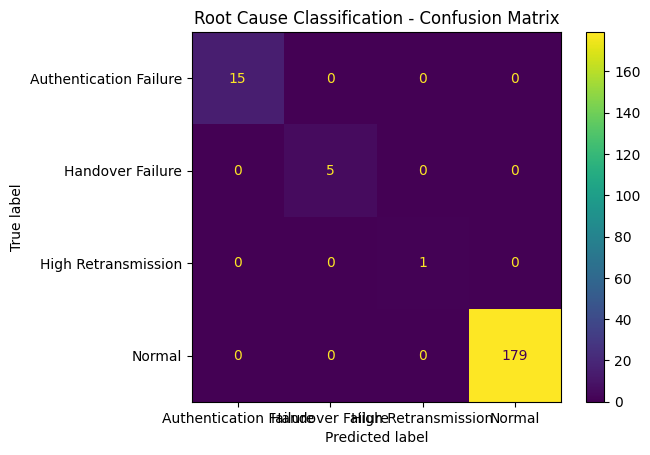

In [114]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

disp.plot()
plt.title("Root Cause Classification - Confusion Matrix")
plt.show()

In [115]:
#Feature Importance

importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

importance_df

,feature,importance
4,authentication_failures,0.275928
1,total_failures,0.258570
5,handover_failures,0.140694
3,failure_rate,0.099741
6,total_retransmissions,0.086094
2,avg_retransmission,0.077555
0,total_events,0.061418


"I also examined feature importance from the Random Forest to understand which UE-level behavioral features contributed most to root-cause classification."

Don't change the dataset just to make the accuracy lower. A lower accuracy number isn't automatically a better model.

Instead, after we finish understanding this baseline, we can create a more realistic synthetic dataset with overlapping/noisy patterns, where a UE can have authentication failures, handover failures and retransmissions in different combinations. That will make the ML problem more realistic and give us a better demonstration of generalization.

For now, run the confusion matrix and feature importance cells above and send me the output.

"I used Random Forest feature importance to understand which UE-level behavioral features contributed most to root-cause classification. In this synthetic dataset, authentication failures and total failures had the highest importance, followed by handover failures and failure-rate-related features."

But add an important qualification:

"Because the dataset and labels were synthetically generated using domain-informed rules, these importance values should be treated as project-level observations rather than evidence of production telecom behavior."

"Applied NLP techniques to identify critical events and abnormal behavior."

Event text
    ↓
Text preprocessing
    ↓
TF-IDF
    ↓
Numerical feature matrix
    ↓
NLP classification


Rule-based approach
        vs
TF-IDF + ML approach

In [116]:
df["event"].value_counts()

,count
event,
Connection Request,895
Connection Setup,895
Registration Request,895
Authentication Request,895
Authentication Response,895
Registration Accept,895
Connection Release,895
UL Retransmission,542
Authentication Failure,374


TF-IDF (Term Frequency–Inverse Document Frequency).
Event text
   ↓
TF-IDF Vectorizer
   ↓
Numerical representation
   ↓
ML model

In [117]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2)
)

X_text = vectorizer.fit_transform(df["event"])

print("TF-IDF matrix shape:", X_text.shape)

TF-IDF matrix shape: (7509, 24)


df["event"] contains text such as:

Authentication Failure
Authentication Request
Handover Failure
UL Retransmission

TFidfVectorizer converts these words into numbers.

ngram_range=(1, 2) means we capture:

1-word terms

authentication
failure
handover
retransmission

and 2-word combinations

authentication failure
authentication request
handover failure
ul retransmission


This is particularly useful for technical logs because phrases such as "Authentication Failure" carry more meaning than the individual words separately.

Run the cell and send me the output of TF-IDF matrix shape. Then we'll inspect what features TF-IDF actually created before building the NLP classifier.

In [118]:
feature_names = vectorizer.get_feature_names_out()

print("Number of features:", len(feature_names))
print("\nTF-IDF Features:")

for feature in feature_names:
    print(feature)

Number of features: 24

TF-IDF Features:
accept
authentication
authentication failure
authentication request
authentication response
connection
connection release
connection request
connection setup
failure
handover
handover failure
registration
registration accept
registration reject
registration request
reject
release
request
response
retransmission
setup
ul
ul retransmission


"I used NLP-based TF-IDF feature extraction to transform unstructured technical log-event text into numerical features suitable for machine-learning models."

That's a good interview statement because it is directly supported by what we have built.

One important point: TF-IDF itself is not classification. Right now we've only converted text → numbers.

In [119]:
df["event_category"].value_counts()

,count
event_category,
Connection,2685
Authentication,2164
Registration,1895
Retransmission,542
Mobility,223


How many categories we have.
Whether every category has enough examples.
Whether the classes are highly imbalanced.

event text
     ↓
TF-IDF
     ↓
Train/Test Split
     ↓
Logistic Regression
     ↓
Predicted Event Category
     ↓
Precision / Recall / F1

Run only this cell for now and send me the output. Then we'll build the classifier one step at a time.

In [120]:
from sklearn.model_selection import train_test_split

X_text_train, X_text_test, y_text_train, y_text_test = train_test_split(
    X_text,
    df["event_category"],
    test_size=0.20,
    random_state=42,
    stratify=df["event_category"]
)

print("Training samples:", X_text_train.shape[0])
print("Testing samples :", X_text_test.shape[0])

print("\nTraining distribution:")
print(y_text_train.value_counts())

print("\nTesting distribution:")
print(y_text_test.value_counts())

Training samples: 6007
Testing samples : 1502

Training distribution:
event_category
Connection        2148
Authentication    1731
Registration      1516
Retransmission     434
Mobility           178
Name: count, dtype: int64

Testing distribution:
event_category
Connection        537
Authentication    433
Registration      379
Retransmission    108
Mobility           45
Name: count, dtype: int64


Without stratify, we could accidentally get very different proportions of categories in training and testing.

With:

In [121]:
stratify=df["event_category"]

the train and test datasets maintain approximately the same category distribution.

For example, Mobility is only 223 out of 7,509 events. Stratification helps ensure that Mobility examples appear in both training and testing sets.

We'll use Logistic Regression as our baseline classifier.

Why?

It works very well with TF-IDF text features.
It is fast.
It is easy to explain in an interview.
It provides a strong baseline before trying more complex models.

In [122]:
from sklearn.linear_model import LogisticRegression

nlp_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

nlp_model.fit(
    X_text_train,
    y_text_train
)

print("NLP model training completed.")

NLP model training completed.


In [123]:
nlp_model.fit(X_text_train, y_text_train)

LogisticRegression(max_iter=1000, random_state=42)

One important point: because our synthetic event categories were created using rules from the event names, this classification task is relatively easy. Later, we'll discuss how to make the project more realistic.

Run the cell above.

In [124]:
#NLP prediction and evaluation.

In [125]:
y_text_pred = nlp_model.predict(X_text_test)

print("Predictions completed.")
print("Number of predictions:", len(y_text_pred))

Predictions completed.
Number of predictions: 1502


In [126]:
comparison_nlp = pd.DataFrame({
    "Actual": y_text_test.values,
    "Predicted": y_text_pred
})

comparison_nlp.head(20)

,Actual,Predicted
0,Authentication,Authentication
1,Registration,Registration
2,Registration,Registration
3,Authentication,Authentication
4,Authentication,Authentication
5,Connection,Connection
6,Retransmission,Retransmission
7,Connection,Connection
8,Authentication,Authentication
9,Connection,Connection


In [127]:
from sklearn.metrics import classification_report

print(classification_report(
    y_text_test,
    y_text_pred,
    zero_division=0
))

                precision    recall  f1-score   support

Authentication       1.00      1.00      1.00       433
    Connection       1.00      1.00      1.00       537
      Mobility       1.00      1.00      1.00        45
  Registration       1.00      1.00      1.00       379
Retransmission       1.00      1.00      1.00       108

      accuracy                           1.00      1502
     macro avg       1.00      1.00      1.00      1502
  weighted avg       1.00      1.00      1.00      1502



If you get extremely high or even 100% accuracy, don't claim that the NLP model is production-ready.

Your synthetic data contains very distinctive phrases:

"Authentication Failure"
"Handover Failure"
"UL Retransmission"
"Connection Request"

and the target categories were themselves generated from those event names.

So the model has a relatively easy classification problem.

A truthful interview explanation would be:

"I implemented a TF-IDF plus Logistic Regression NLP baseline to classify technical modem-log events into categories. The synthetic dataset produced strong classification performance because the event terminology is highly distinctive. I would validate the approach on real labeled modem logs before making production-level performance claims."

That's actually a stronger interview answer than simply saying "my model achieved 100%."

We should not present this as evidence that the NLP model will achieve 100% on real QXDM logs.

Our synthetic data has very distinctive terminology:

Authentication Failure → Authentication
Handover Failure       → Mobility
UL Retransmission      → Retransmission
Connection Request     → Connection
Registration Reject    → Registration

And we created event_category using rules based on the event text itself.

So the model has an easy learning problem.

For your project, that's okay—we're demonstrating the complete NLP pipeline.

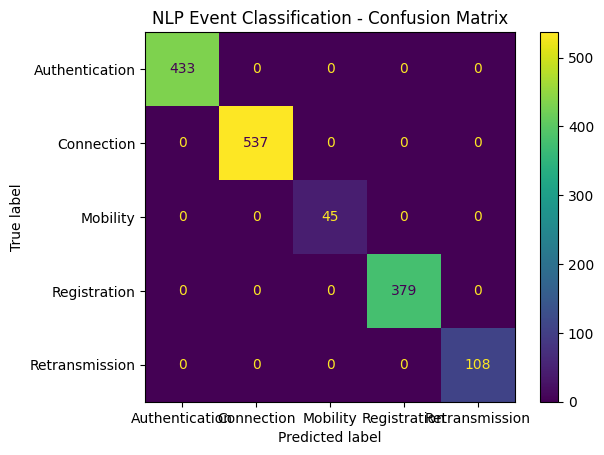

In [128]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_nlp = confusion_matrix(
    y_text_test,
    y_text_pred,
    labels=nlp_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nlp,
    display_labels=nlp_model.classes_
)

disp.plot()

plt.title("NLP Event Classification - Confusion Matrix")
plt.show()

In [129]:
feature_names = vectorizer.get_feature_names_out()

for i, category in enumerate(nlp_model.classes_):

    coefficients = nlp_model.coef_[i]

    top_indices = coefficients.argsort()[-5:][::-1]

    print(f"\nCategory: {category}")

    for index in top_indices:
        print(
            f"  {feature_names[index]}: "
            f"{coefficients[index]:.3f}"
        )


Category: Authentication
  authentication: 4.963
  authentication request: 2.914
  authentication failure: 2.373
  response: 2.145
  authentication response: 2.145

Category: Connection
  connection: 4.718
  connection request: 2.964
  setup: 2.155
  connection setup: 2.155
  connection release: 2.154

Category: Mobility
  handover failure: 3.286
  handover: 3.286
  failure: 1.918
  reject: -0.193
  registration reject: -0.193

Category: Registration
  registration: 4.635
  registration request: 2.989
  accept: 2.198
  registration accept: 2.198
  reject: 1.531

Category: Retransmission
  ul retransmission: 3.173
  ul: 3.173
  retransmission: 3.173
  reject: -0.227
  registration reject: -0.227


"I used TF-IDF to transform technical modem-log events into numerical text features and Logistic Regression to classify those events into protocol-related categories. I also inspected the learned coefficients to understand which technical terms contributed to each classification."'

In [130]:
df["nlp_predicted_category"] = nlp_model.predict(
    vectorizer.transform(df["event"])
)

df[[
    "event",
    "event_category",
    "nlp_predicted_category"
]].head(20)

,event,event_category,nlp_predicted_category
0,Connection Request,Connection,Connection
1,Connection Setup,Connection,Connection
2,Registration Request,Registration,Registration
3,Authentication Request,Authentication,Authentication
4,Authentication Response,Authentication,Authentication
5,Registration Accept,Registration,Registration
6,Connection Release,Connection,Connection
7,Authentication Failure,Authentication,Authentication
8,Authentication Failure,Authentication,Authentication
9,Authentication Failure,Authentication,Authentication


In [131]:
nlp_category_counts = pd.crosstab(
    df["ue_id"],
    df["nlp_predicted_category"]
)

nlp_category_counts.head()

nlp_predicted_category,Authentication,Connection,Mobility,Registration,Retransmission
ue_id,,,,,
1001,2,3,0,2,0
1002,5,0,3,1,2
1003,2,3,0,2,0
1004,2,3,0,2,0
1005,2,3,0,2,0


In [132]:
df["nlp_predicted_category"] = nlp_model.predict(
    vectorizer.transform(df["event"])
)

df[[
    "event",
    "event_category",
    "nlp_predicted_category"
]].head(20)

,event,event_category,nlp_predicted_category
0,Connection Request,Connection,Connection
1,Connection Setup,Connection,Connection
2,Registration Request,Registration,Registration
3,Authentication Request,Authentication,Authentication
4,Authentication Response,Authentication,Authentication
5,Registration Accept,Registration,Registration
6,Connection Release,Connection,Connection
7,Authentication Failure,Authentication,Authentication
8,Authentication Failure,Authentication,Authentication
9,Authentication Failure,Authentication,Authentication


In [133]:
nlp_category_counts = pd.crosstab(
    df["ue_id"],
    df["nlp_predicted_category"]
)

nlp_category_counts.head()

nlp_predicted_category,Authentication,Connection,Mobility,Registration,Retransmission
ue_id,,,,,
1001,2,3,0,2,0
1002,5,0,3,1,2
1003,2,3,0,2,0
1004,2,3,0,2,0
1005,2,3,0,2,0


In [134]:
nlp_category_counts = nlp_category_counts.fillna(0)

nlp_category_counts.head()

nlp_predicted_category,Authentication,Connection,Mobility,Registration,Retransmission
ue_id,,,,,
1001,2,3,0,2,0
1002,5,0,3,1,2
1003,2,3,0,2,0
1004,2,3,0,2,0
1005,2,3,0,2,0


In [135]:
nlp_category_counts = nlp_category_counts.rename(columns={
    "Authentication": "nlp_authentication_count",
    "Connection": "nlp_connection_count",
    "Mobility": "nlp_mobility_count",
    "Registration": "nlp_registration_count",
    "Retransmission": "nlp_retransmission_count"
})

nlp_category_counts.head()

nlp_predicted_category,nlp_authentication_count,nlp_connection_count,nlp_mobility_count,nlp_registration_count,nlp_retransmission_count
ue_id,,,,,
1001,2,3,0,2,0
1002,5,0,3,1,2
1003,2,3,0,2,0
1004,2,3,0,2,0
1005,2,3,0,2,0


In [136]:
features_enhanced = features.merge(
    nlp_category_counts,
    on="ue_id",
    how="left"
)

features_enhanced.head()

,ue_id,total_events,total_failures,avg_retransmission,anomaly_prediction,anomaly_score,is_anomaly,authentication_failures,handover_failures,total_retransmissions,failure_rate,root_cause,root_causes,primary_root_cause,nlp_authentication_count,nlp_connection_count,nlp_mobility_count,nlp_registration_count,nlp_retransmission_count
0,1001,7,0,0.0,1,0.19099,False,0.0,0.0,0.0,0.000000,Other,Normal,Normal,2,3,0,2,0
1,1002,11,9,13.5,-1,-0.08800,True,5.0,3.0,27.0,0.818182,Authentication Failure,"Authentication Failure, Handover Failure, High...",Authentication Failure,5,0,3,1,2
2,1003,7,0,0.0,1,0.19099,False,0.0,0.0,0.0,0.000000,Other,Normal,Normal,2,3,0,2,0
3,1004,7,0,0.0,1,0.19099,False,0.0,0.0,0.0,0.000000,Other,Normal,Normal,2,3,0,2,0
4,1005,7,0,0.0,1,0.19099,False,0.0,0.0,0.0,0.000000,Other,Normal,Normal,2,3,0,2,0


Don't replace your original features with the NLP features.

Keep both.

For example:

authentication_failures

is a domain-specific engineered feature, while:

nlp_authentication_count

is an NLP-derived feature.

That distinction is valuable during an interview.

In [137]:
nlp_category_counts = nlp_category_counts.fillna(0)

In [138]:
nlp_category_counts = nlp_category_counts.rename(columns={
    "Authentication": "nlp_authentication_count",
    "Connection": "nlp_connection_count",
    "Mobility": "nlp_mobility_count",
    "Registration": "nlp_registration_count",
    "Retransmission": "nlp_retransmission_count"
})

In [139]:
features_enhanced = features.merge(
    nlp_category_counts,
    on="ue_id",
    how="left"
)

features_enhanced.head()

,ue_id,total_events,total_failures,avg_retransmission,anomaly_prediction,anomaly_score,is_anomaly,authentication_failures,handover_failures,total_retransmissions,failure_rate,root_cause,root_causes,primary_root_cause,nlp_authentication_count,nlp_connection_count,nlp_mobility_count,nlp_registration_count,nlp_retransmission_count
0,1001,7,0,0.0,1,0.19099,False,0.0,0.0,0.0,0.000000,Other,Normal,Normal,2,3,0,2,0
1,1002,11,9,13.5,-1,-0.08800,True,5.0,3.0,27.0,0.818182,Authentication Failure,"Authentication Failure, Handover Failure, High...",Authentication Failure,5,0,3,1,2
2,1003,7,0,0.0,1,0.19099,False,0.0,0.0,0.0,0.000000,Other,Normal,Normal,2,3,0,2,0
3,1004,7,0,0.0,1,0.19099,False,0.0,0.0,0.0,0.000000,Other,Normal,Normal,2,3,0,2,0
4,1005,7,0,0.0,1,0.19099,False,0.0,0.0,0.0,0.000000,Other,Normal,Normal,2,3,0,2,0


In [140]:
print("Shape:", features_enhanced.shape)

print("\nColumns:")
print(features_enhanced.columns.tolist())

print("\nFirst 5 rows:")
display(features_enhanced.head())

Shape: (1000, 19)

Columns:
['ue_id', 'total_events', 'total_failures', 'avg_retransmission', 'anomaly_prediction', 'anomaly_score', 'is_anomaly', 'authentication_failures', 'handover_failures', 'total_retransmissions', 'failure_rate', 'root_cause', 'root_causes', 'primary_root_cause', 'nlp_authentication_count', 'nlp_connection_count', 'nlp_mobility_count', 'nlp_registration_count', 'nlp_retransmission_count']

First 5 rows:


,ue_id,total_events,total_failures,avg_retransmission,anomaly_prediction,anomaly_score,is_anomaly,authentication_failures,handover_failures,total_retransmissions,failure_rate,root_cause,root_causes,primary_root_cause,nlp_authentication_count,nlp_connection_count,nlp_mobility_count,nlp_registration_count,nlp_retransmission_count
0,1001,7,0,0.0,1,0.19099,False,0.0,0.0,0.0,0.000000,Other,Normal,Normal,2,3,0,2,0
1,1002,11,9,13.5,-1,-0.08800,True,5.0,3.0,27.0,0.818182,Authentication Failure,"Authentication Failure, Handover Failure, High...",Authentication Failure,5,0,3,1,2
2,1003,7,0,0.0,1,0.19099,False,0.0,0.0,0.0,0.000000,Other,Normal,Normal,2,3,0,2,0
3,1004,7,0,0.0,1,0.19099,False,0.0,0.0,0.0,0.000000,Other,Normal,Normal,2,3,0,2,0
4,1005,7,0,0.0,1,0.19099,False,0.0,0.0,0.0,0.000000,Other,Normal,Normal,2,3,0,2,0


In [141]:
enhanced_feature_columns = [
    "total_events",
    "total_failures",
    "avg_retransmission",
    "failure_rate",
    "authentication_failures",
    "handover_failures",
    "total_retransmissions",
    "nlp_authentication_count",
    "nlp_connection_count",
    "nlp_mobility_count",
    "nlp_registration_count",
    "nlp_retransmission_count"
]

X_enhanced = features_enhanced[enhanced_feature_columns]
y_enhanced = features_enhanced["primary_root_cause"]

print("Number of features:", len(enhanced_feature_columns))
print("\nFeatures:")
for feature in enhanced_feature_columns:
    print(feature)

Number of features: 12

Features:
total_events
total_failures
avg_retransmission
failure_rate
authentication_failures
handover_failures
total_retransmissions
nlp_authentication_count
nlp_connection_count
nlp_mobility_count
nlp_registration_count
nlp_retransmission_count


"Before training the enhanced model, I separated predictor variables from model-generated outputs and the target variable to avoid target leakage. I combined domain-specific telecom features with NLP-derived behavioral features."

In [142]:
from sklearn.model_selection import train_test_split

X_enhanced_train, X_enhanced_test, y_enhanced_train, y_enhanced_test = train_test_split(
    X_enhanced,
    y_enhanced,
    test_size=0.20,
    random_state=42,
    stratify=y_enhanced
)

print("Training samples:", X_enhanced_train.shape[0])
print("Testing samples :", X_enhanced_test.shape[0])

print("\nTraining distribution:")
print(y_enhanced_train.value_counts())

print("\nTesting distribution:")
print(y_enhanced_test.value_counts())

Training samples: 800
Testing samples : 200

Training distribution:
primary_root_cause
Normal                    716
Authentication Failure     62
Handover Failure           18
High Retransmission         4
Name: count, dtype: int64

Testing distribution:
primary_root_cause
Normal                    179
Authentication Failure     15
Handover Failure            5
High Retransmission         1
Name: count, dtype: int64


Why are we doing a new split?

Because our enhanced dataset contains additional NLP-derived features.

We want to evaluate the enhanced model on a held-out test set, rather than training and testing on the same data.

Our pipeline is now:

Enhanced UE Dataset
        │
        ├── Telecom features
        │
        └── NLP features
                ↓
          80/20 split
                ↓
        Random Forest
                ↓
        Root-cause prediction
                ↓
       Precision / Recall / F1


In [143]:
from sklearn.ensemble import RandomForestClassifier

enhanced_rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

enhanced_rf_model.fit(
    X_enhanced_train,
    y_enhanced_train
)

print("Enhanced Random Forest training completed.")

Enhanced Random Forest training completed.


In [144]:
y_enhanced_pred = enhanced_rf_model.predict(
    X_enhanced_test
)

print("Predictions completed.")
print("Number of predictions:", len(y_enhanced_pred))

Predictions completed.
Number of predictions: 200


In [145]:
from sklearn.metrics import classification_report

print(classification_report(
    y_enhanced_test,
    y_enhanced_pred,
    zero_division=0
))

                        precision    recall  f1-score   support

Authentication Failure       1.00      1.00      1.00        15
      Handover Failure       1.00      1.00      1.00         5
   High Retransmission       1.00      1.00      1.00         1
                Normal       1.00      1.00      1.00       179

              accuracy                           1.00       200
             macro avg       1.00      1.00      1.00       200
          weighted avg       1.00      1.00      1.00       200



In [146]:
enhanced_importance_df = pd.DataFrame({
    "feature": enhanced_feature_columns,
    "importance": enhanced_rf_model.feature_importances_
})

enhanced_importance_df = enhanced_importance_df.sort_values(
    "importance",
    ascending=False
)

enhanced_importance_df

,feature,importance
4,authentication_failures,0.191189
1,total_failures,0.185292
7,nlp_authentication_count,0.133071
5,handover_failures,0.096732
9,nlp_mobility_count,0.095555
3,failure_rate,0.070606
2,avg_retransmission,0.064080
6,total_retransmissions,0.041743
0,total_events,0.038197
11,nlp_retransmission_count,0.034485


In [147]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Original model metrics
original_accuracy = accuracy_score(y_test, y_pred)
original_precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
original_recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
original_f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

# Enhanced model metrics
enhanced_accuracy = accuracy_score(y_enhanced_test, y_enhanced_pred)
enhanced_precision = precision_score(
    y_enhanced_test, y_enhanced_pred, average="weighted", zero_division=0
)
enhanced_recall = recall_score(
    y_enhanced_test, y_enhanced_pred, average="weighted", zero_division=0
)
enhanced_f1 = f1_score(
    y_enhanced_test, y_enhanced_pred, average="weighted", zero_division=0
)

# Create comparison table
comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Original Model": [
        original_accuracy,
        original_precision,
        original_recall,
        original_f1
    ],
    "Enhanced Model": [
        enhanced_accuracy,
        enhanced_precision,
        enhanced_recall,
        enhanced_f1
    ]
})

comparison_df

,Metric,Original Model,Enhanced Model
0,Accuracy,1.0,1.0
1,Precision,1.0,1.0
2,Recall,1.0,1.0
3,F1 Score,1.0,1.0


In [148]:
comparison_df["Difference"] = (
    comparison_df["Enhanced Model"]
    - comparison_df["Original Model"]
)

comparison_df

,Metric,Original Model,Enhanced Model,Difference
0,Accuracy,1.0,1.0,0.0
1,Precision,1.0,1.0,0.0
2,Recall,1.0,1.0,0.0
3,F1 Score,1.0,1.0,0.0


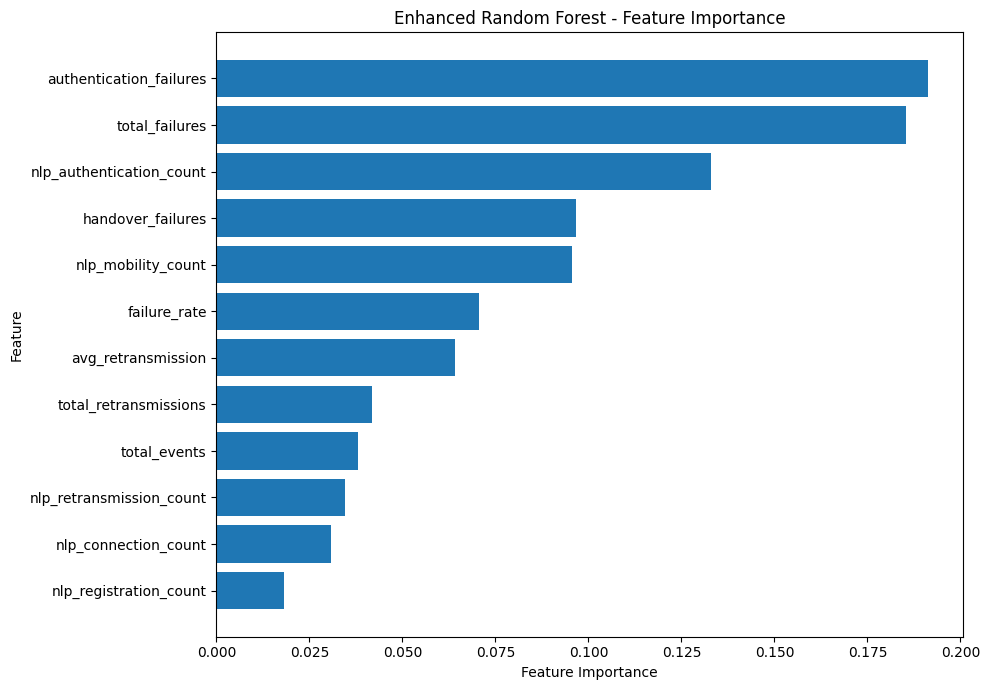

In [149]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.barh(
    enhanced_importance_df["feature"],
    enhanced_importance_df["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Enhanced Random Forest - Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

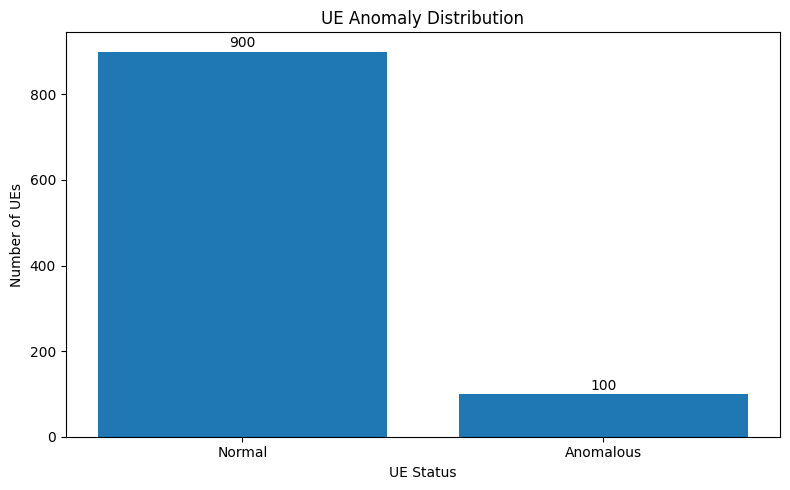

In [150]:
import matplotlib.pyplot as plt

# Count normal and anomalous UEs
anomaly_counts = features_enhanced["is_anomaly"].value_counts()

# Convert boolean values to readable labels
labels = ["Normal", "Anomalous"]

values = [
    anomaly_counts.get(False, 0),
    anomaly_counts.get(True, 0)
]

plt.figure(figsize=(8, 5))

plt.bar(labels, values)

plt.xlabel("UE Status")
plt.ylabel("Number of UEs")
plt.title("UE Anomaly Distribution")

# Display values on top of bars
for i, value in enumerate(values):
    plt.text(i, value + 10, str(value), ha="center")

plt.tight_layout()
plt.show()

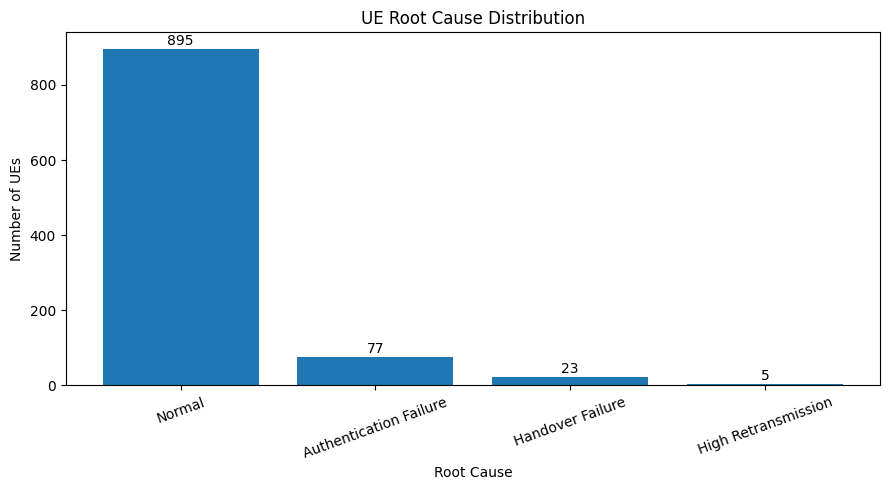

In [151]:
import matplotlib.pyplot as plt

root_cause_counts = (
    features_enhanced["primary_root_cause"]
    .value_counts()
)

plt.figure(figsize=(9, 5))

plt.bar(
    root_cause_counts.index,
    root_cause_counts.values
)

plt.xlabel("Root Cause")
plt.ylabel("Number of UEs")
plt.title("UE Root Cause Distribution")

plt.xticks(rotation=20)

for i, value in enumerate(root_cause_counts.values):
    plt.text(
        i,
        value + 10,
        str(value),
        ha="center"
    )

plt.tight_layout()
plt.show()

In [152]:
ue_id = 1002

ue_analysis = features_enhanced[
    features_enhanced["ue_id"] == ue_id
]

ue_analysis.T

,1
ue_id,1002
total_events,11
total_failures,9
avg_retransmission,13.5
anomaly_prediction,-1
anomaly_score,-0.088
is_anomaly,True
authentication_failures,5.0
handover_failures,3.0
total_retransmissions,27.0


In [153]:
ue = ue_analysis.iloc[0]

print("=" * 50)
print(f"UE TECHNICAL ANALYSIS - UE {int(ue['ue_id'])}")
print("=" * 50)

print(f"Anomaly Status       : {'ANOMALOUS' if ue['is_anomaly'] else 'NORMAL'}")
print(f"Primary Root Cause   : {ue['primary_root_cause']}")
print()
print("----- Telecom Metrics -----")
print(f"Total Events         : {int(ue['total_events'])}")
print(f"Total Failures       : {int(ue['total_failures'])}")
print(f"Authentication Failures : {int(ue['authentication_failures'])}")
print(f"Handover Failures    : {int(ue['handover_failures'])}")
print(f"Total Retransmissions: {int(ue['total_retransmissions'])}")
print(f"Failure Rate         : {ue['failure_rate']:.2%}")
print()
print("----- NLP Analysis -----")
print(f"Authentication Events: {int(ue['nlp_authentication_count'])}")
print(f"Connection Events    : {int(ue['nlp_connection_count'])}")
print(f"Mobility Events      : {int(ue['nlp_mobility_count'])}")
print(f"Registration Events  : {int(ue['nlp_registration_count'])}")
print(f"Retransmission Events: {int(ue['nlp_retransmission_count'])}")
print("=" * 50)

UE TECHNICAL ANALYSIS - UE 1002
Anomaly Status       : ANOMALOUS
Primary Root Cause   : Authentication Failure

----- Telecom Metrics -----
Total Events         : 11
Total Failures       : 9
Authentication Failures : 5
Handover Failures    : 3
Total Retransmissions: 27
Failure Rate         : 81.82%

----- NLP Analysis -----
Authentication Events: 5
Connection Events    : 0
Mobility Events      : 3
Registration Events  : 1
Retransmission Events: 2


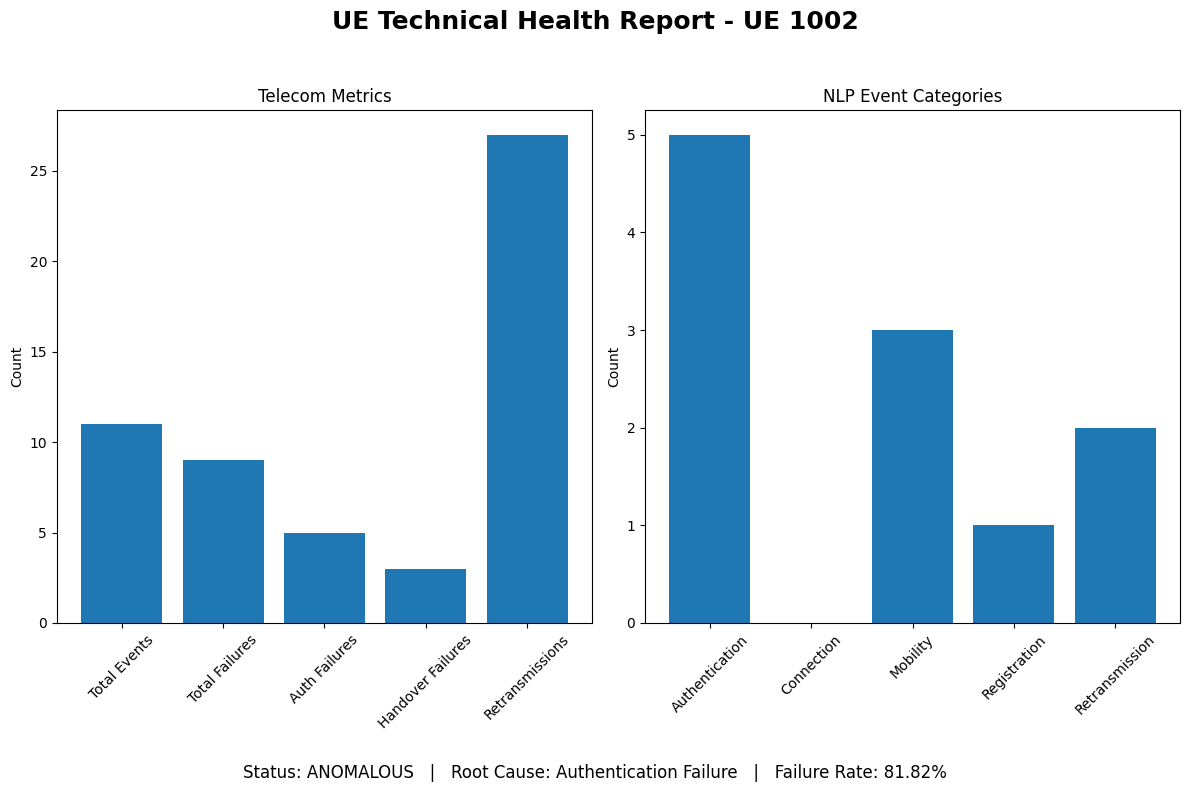

In [154]:
import matplotlib.pyplot as plt

ue = ue_analysis.iloc[0]

# -----------------------------
# Data
# -----------------------------
telecom_metrics = {
    "Total Events": ue["total_events"],
    "Total Failures": ue["total_failures"],
    "Auth Failures": ue["authentication_failures"],
    "Handover Failures": ue["handover_failures"],
    "Retransmissions": ue["total_retransmissions"]
}

nlp_metrics = {
    "Authentication": ue["nlp_authentication_count"],
    "Connection": ue["nlp_connection_count"],
    "Mobility": ue["nlp_mobility_count"],
    "Registration": ue["nlp_registration_count"],
    "Retransmission": ue["nlp_retransmission_count"]
}

# -----------------------------
# Create figure
# -----------------------------
fig = plt.figure(figsize=(12, 8))

# Title
fig.suptitle(
    f"UE Technical Health Report - UE {int(ue['ue_id'])}",
    fontsize=18,
    fontweight="bold"
)

# -----------------------------
# Telecom metrics
# -----------------------------
ax1 = plt.subplot(1, 2, 1)

ax1.bar(
    telecom_metrics.keys(),
    telecom_metrics.values()
)

ax1.set_title("Telecom Metrics")
ax1.set_ylabel("Count")
ax1.tick_params(axis="x", rotation=45)

# -----------------------------
# NLP metrics
# -----------------------------
ax2 = plt.subplot(1, 2, 2)

ax2.bar(
    nlp_metrics.keys(),
    nlp_metrics.values()
)

ax2.set_title("NLP Event Categories")
ax2.set_ylabel("Count")
ax2.tick_params(axis="x", rotation=45)

# -----------------------------
# Summary
# -----------------------------
fig.text(
    0.5,
    0.02,
    f"Status: {'ANOMALOUS' if ue['is_anomaly'] else 'NORMAL'}   |   "
    f"Root Cause: {ue['primary_root_cause']}   |   "
    f"Failure Rate: {ue['failure_rate']:.2%}",
    ha="center",
    fontsize=12
)

plt.tight_layout(rect=[0, 0.06, 1, 0.95])

plt.show()

In [155]:
import os

models_path = "/content/models"

os.makedirs(models_path, exist_ok=True)

print("Models directory created:")
print(models_path)

Models directory created:
/content/models


In [156]:
import joblib

print("Joblib imported successfully")

Joblib imported successfully


In [157]:
vectorizer

TfidfVectorizer(ngram_range=(1, 2))

In [158]:
vectorizer.fit_transform(df["event"])

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 22527 stored elements and shape (7509, 24)>

In [159]:
vectorizer_path = "/content/models/tfidf_vectorizer.joblib"

joblib.dump(
    vectorizer,
    vectorizer_path
)

print("TF-IDF vectorizer saved:")
print(vectorizer_path)

TF-IDF vectorizer saved:
/content/models/tfidf_vectorizer.joblib


In [160]:
nlp_model

LogisticRegression(max_iter=1000, random_state=42)

In [161]:
nlp_model.fit(X_text_train, y_text_train)

LogisticRegression(max_iter=1000, random_state=42)

In [162]:
nlp_model_path = "/content/models/nlp_classifier.joblib"

joblib.dump(
    nlp_model,
    nlp_model_path
)

print("NLP classifier saved:")
print(nlp_model_path)

NLP classifier saved:
/content/models/nlp_classifier.joblib


In [163]:
enhanced_rf_model

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

In [164]:
root_cause_model_path = "/content/models/root_cause_model.joblib"

joblib.dump(
    enhanced_rf_model,
    root_cause_model_path
)

print("Root cause model saved:")
print(root_cause_model_path)

Root cause model saved:
/content/models/root_cause_model.joblib


In [165]:
enhanced_feature_columns

['total_events',
 'total_failures',
 'avg_retransmission',
 'failure_rate',
 'authentication_failures',
 'handover_failures',
 'total_retransmissions',
 'nlp_authentication_count',
 'nlp_connection_count',
 'nlp_mobility_count',
 'nlp_registration_count',
 'nlp_retransmission_count']

In [166]:
import json

feature_metadata = {
    "feature_columns": enhanced_feature_columns
}

metadata_path = "/content/models/feature_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(feature_metadata, f, indent=4)

print("Feature metadata saved:")
print(metadata_path)

Feature metadata saved:
/content/models/feature_metadata.json


In [167]:
import os

print("Saved model files:")
print()

for file in os.listdir("/content/models"):
    print(file)

Saved model files:

root_cause_model.joblib
feature_metadata.json
nlp_classifier.joblib
tfidf_vectorizer.joblib


In [168]:
import joblib
import json

# Load TF-IDF vectorizer
loaded_vectorizer = joblib.load(
    "/content/models/tfidf_vectorizer.joblib"
)

# Load NLP classifier
loaded_nlp_model = joblib.load(
    "/content/models/nlp_classifier.joblib"
)

# Load root-cause model
loaded_root_cause_model = joblib.load(
    "/content/models/root_cause_model.joblib"
)

# Load metadata
with open("/content/models/feature_metadata.json", "r") as f:
    loaded_metadata = json.load(f)

print("All models loaded successfully!")
print()

print("Vectorizer:", type(loaded_vectorizer))
print("NLP Model:", type(loaded_nlp_model))
print("Root Cause Model:", type(loaded_root_cause_model))
print()

print("Root cause features:")
print(loaded_metadata["feature_columns"])

All models loaded successfully!

Vectorizer: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>
NLP Model: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Root Cause Model: <class 'sklearn.ensemble._forest.RandomForestClassifier'>

Root cause features:
['total_events', 'total_failures', 'avg_retransmission', 'failure_rate', 'authentication_failures', 'handover_failures', 'total_retransmissions', 'nlp_authentication_count', 'nlp_connection_count', 'nlp_mobility_count', 'nlp_registration_count', 'nlp_retransmission_count']


In [169]:
new_event = ["Authentication Failure"]

new_event_tfidf = loaded_vectorizer.transform(new_event)

predicted_category = loaded_nlp_model.predict(
    new_event_tfidf
)

print("Event:", new_event[0])
print("Predicted Category:", predicted_category[0])

Event: Authentication Failure
Predicted Category: Authentication


In [170]:
vectorizer = joblib.load(
    "models/tfidf_vectorizer.joblib"
)

nlp_model = joblib.load(
    "models/nlp_classifier.joblib"
)

root_cause_model = joblib.load(
    "models/root_cause_model.joblib"
)

In [171]:
def analyze_ue(log_data):
    ...
    return result

In [172]:
import joblib
import json

# Load saved objects
loaded_vectorizer = joblib.load(
    "/content/models/tfidf_vectorizer.joblib"
)

loaded_nlp_model = joblib.load(
    "/content/models/nlp_classifier.joblib"
)

loaded_root_cause_model = joblib.load(
    "/content/models/root_cause_model.joblib"
)

with open("/content/models/feature_metadata.json", "r") as f:
    loaded_metadata = json.load(f)

print("=" * 60)
print("SAVED MODEL VERIFICATION")
print("=" * 60)

print("TF-IDF Vectorizer :", type(loaded_vectorizer).__name__)
print("NLP Classifier    :", type(loaded_nlp_model).__name__)
print("Root Cause Model  :", type(loaded_root_cause_model).__name__)

print("\nNumber of root-cause features:",
      len(loaded_metadata["feature_columns"]))

print("\nFeature columns:")
for feature in loaded_metadata["feature_columns"]:
    print(" -", feature)

print("\nAll saved objects loaded successfully!")

SAVED MODEL VERIFICATION
TF-IDF Vectorizer : TfidfVectorizer
NLP Classifier    : LogisticRegression
Root Cause Model  : RandomForestClassifier

Number of root-cause features: 12

Feature columns:
 - total_events
 - total_failures
 - avg_retransmission
 - failure_rate
 - authentication_failures
 - handover_failures
 - total_retransmissions
 - nlp_authentication_count
 - nlp_connection_count
 - nlp_mobility_count
 - nlp_registration_count
 - nlp_retransmission_count

All saved objects loaded successfully!


In [173]:
test_log = """
2026-09-24 10:00:00.100 | LTE | NAS | Authentication Failure | UE=2001 | Cause=21
2026-09-24 10:00:01.200 | LTE | NAS | Authentication Failure | UE=2001 | Cause=21
2026-09-24 10:00:02.300 | LTE | NAS | Authentication Failure | UE=2001 | Cause=21
2026-09-24 10:00:03.400 | LTE | NAS | Authentication Failure | UE=2001 | Cause=21
2026-09-24 10:00:04.500 | NR | RRC | Handover Failure | UE=2001 | Cause=HO_FAILURE
2026-09-24 10:00:05.600 | LTE | MAC | UL Retransmission | UE=2001 | Count=12
2026-09-24 10:00:06.700 | LTE | MAC | UL Retransmission | UE=2001 | Count=15
2026-09-24 10:00:07.800 | LTE | NAS | Registration Reject | UE=2001 | Cause=15
"""

result = analyze_ue(test_log)

print(result)

{'timestamp': '2026-08-25 10:32:02.835', 'rat': 'LTE', 'protocol': 'RRC', 'event': 'Connection Release', 'ue_id': '2000', 'cause': None, 'count': None}


In [174]:
import inspect

print(inspect.getsource(analyze_ue))

def analyze_ue(log_data):
    ...
    return result



In [175]:
import pandas as pd

def analyze_ue(log_data):

    # --------------------------------
    # 1. Split raw log into lines
    # --------------------------------
    lines = log_data.strip().split("\n")

    records = []

    # --------------------------------
    # 2. Parse each log line
    # --------------------------------
    for line in lines:

        result = parse_log_line(line)

        if result is not None:
            records.append(result)

    # Check whether parsing worked
    if len(records) == 0:
        return {
            "status": "error",
            "message": "No valid log records found"
        }

    # --------------------------------
    # 3. Create DataFrame
    # --------------------------------
    temp_df = pd.DataFrame(records)

    temp_df["count"] = pd.to_numeric(
        temp_df["count"],
        errors="coerce"
    )

    temp_df["ue_id"] = pd.to_numeric(
        temp_df["ue_id"],
        errors="coerce"
    )

    # --------------------------------
    # 4. Detect failures
    # --------------------------------
    failure_keywords = [
        "failure",
        "reject",
        "timeout",
        "error"
    ]

    pattern = "|".join(failure_keywords)

    temp_df["is_failure"] = (
        temp_df["event"]
        .str.contains(
            pattern,
            case=False,
            na=False
        )
    )

    # --------------------------------
    # 5. NLP prediction
    # --------------------------------
    text_features = loaded_vectorizer.transform(
        temp_df["event"]
    )

    temp_df["nlp_category"] = (
        loaded_nlp_model.predict(text_features)
    )

    # --------------------------------
    # 6. Process each UE
    # --------------------------------
    results = []

    for ue_id, ue_df in temp_df.groupby("ue_id"):

        total_events = len(ue_df)

        total_failures = int(
            ue_df["is_failure"].sum()
        )

        failure_rate = (
            total_failures / total_events
            if total_events > 0
            else 0
        )

        # Authentication failures
        authentication_failures = int(
            ue_df["event"]
            .str.contains(
                "Authentication Failure",
                case=False,
                na=False
            )
            .sum()
        )

        # Handover failures
        handover_failures = int(
            ue_df["event"]
            .str.contains(
                "Handover Failure",
                case=False,
                na=False
            )
            .sum()
        )

        # Retransmission values
        retransmission_rows = ue_df[
            ue_df["event"].str.contains(
                "Retransmission",
                case=False,
                na=False
            )
        ]

        total_retransmissions = (
            retransmission_rows["count"]
            .fillna(0)
            .sum()
        )

        avg_retransmission = (
            retransmission_rows["count"]
            .mean()
        )

        if pd.isna(avg_retransmission):
            avg_retransmission = 0

        # --------------------------------
        # NLP category counts
        # --------------------------------

        nlp_counts = (
            ue_df["nlp_category"]
            .value_counts()
        )

        nlp_authentication_count = int(
            nlp_counts.get("Authentication", 0)
        )

        nlp_connection_count = int(
            nlp_counts.get("Connection", 0)
        )

        nlp_mobility_count = int(
            nlp_counts.get("Mobility", 0)
        )

        nlp_registration_count = int(
            nlp_counts.get("Registration", 0)
        )

        nlp_retransmission_count = int(
            nlp_counts.get("Retransmission", 0)
        )

        # --------------------------------
        # 7. Create model input
        # --------------------------------

        model_input = pd.DataFrame([{

            "total_events":
                total_events,

            "total_failures":
                total_failures,

            "avg_retransmission":
                avg_retransmission,

            "failure_rate":
                failure_rate,

            "authentication_failures":
                authentication_failures,

            "handover_failures":
                handover_failures,

            "total_retransmissions":
                total_retransmissions,

            "nlp_authentication_count":
                nlp_authentication_count,

            "nlp_connection_count":
                nlp_connection_count,

            "nlp_mobility_count":
                nlp_mobility_count,

            "nlp_registration_count":
                nlp_registration_count,

            "nlp_retransmission_count":
                nlp_retransmission_count

        }])

        # Keep exact training feature order
        model_input = model_input[
            loaded_metadata["feature_columns"]
        ]

        # --------------------------------
        # 8. Root cause prediction
        # --------------------------------

        predicted_root_cause = (
            loaded_root_cause_model
            .predict(model_input)[0]
        )

        # --------------------------------
        # 9. Store final result
        # --------------------------------

        results.append({

            "ue_id":
                int(ue_id),

            "total_events":
                int(total_events),

            "total_failures":
                int(total_failures),

            "failure_rate":
                round(float(failure_rate), 4),

            "authentication_failures":
                authentication_failures,

            "handover_failures":
                handover_failures,

            "total_retransmissions":
                int(total_retransmissions),

            "avg_retransmission":
                round(float(avg_retransmission), 2),

            "nlp_authentication_count":
                nlp_authentication_count,

            "nlp_connection_count":
                nlp_connection_count,

            "nlp_mobility_count":
                nlp_mobility_count,

            "nlp_registration_count":
                nlp_registration_count,

            "nlp_retransmission_count":
                nlp_retransmission_count,

            "predicted_root_cause":
                predicted_root_cause

        })

    return results

In [176]:
result = analyze_ue(test_log)

result

[{'ue_id': 2001,
  'total_events': 8,
  'total_failures': 6,
  'failure_rate': 0.75,
  'authentication_failures': 4,
  'handover_failures': 1,
  'total_retransmissions': 27,
  'avg_retransmission': 13.5,
  'nlp_authentication_count': 4,
  'nlp_connection_count': 0,
  'nlp_mobility_count': 1,
  'nlp_registration_count': 1,
  'nlp_retransmission_count': 2,
  'predicted_root_cause': 'Authentication Failure'}]

In [177]:
result = analyze_ue(test_log)
result

[{'ue_id': 2001,
  'total_events': 8,
  'total_failures': 6,
  'failure_rate': 0.75,
  'authentication_failures': 4,
  'handover_failures': 1,
  'total_retransmissions': 27,
  'avg_retransmission': 13.5,
  'nlp_authentication_count': 4,
  'nlp_connection_count': 0,
  'nlp_mobility_count': 1,
  'nlp_registration_count': 1,
  'nlp_retransmission_count': 2,
  'predicted_root_cause': 'Authentication Failure'}]

In [178]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [180]:
import os

PROJECT_PATH = "/content/drive/MyDrive/QXDM_AI_Log_Analyzer"
MODEL_PATH = PROJECT_PATH + "/models"

os.makedirs(MODEL_PATH, exist_ok=True)

print("Model folder created:")
print(MODEL_PATH)

Model folder created:
/content/drive/MyDrive/QXDM_AI_Log_Analyzer/models


In [181]:
objects = [
    "vectorizer",
    "nlp_model",
    "enhanced_rf_model",
    "enhanced_feature_columns"
]

for obj in objects:
    if obj in globals():
        print(f"✅ {obj}")
    else:
        print(f"❌ {obj} -- MISSING")

✅ vectorizer
✅ nlp_model
✅ enhanced_rf_model
✅ enhanced_feature_columns


In [182]:
import joblib
import json
import os

# Permanent Google Drive location
PROJECT_PATH = "/content/drive/MyDrive/QXDM_AI_Log_Analyzer"
MODEL_PATH = PROJECT_PATH + "/models"

os.makedirs(MODEL_PATH, exist_ok=True)

# Save TF-IDF vectorizer
joblib.dump(
    vectorizer,
    MODEL_PATH + "/tfidf_vectorizer.joblib"
)

# Save NLP classifier
joblib.dump(
    nlp_model,
    MODEL_PATH + "/nlp_classifier.joblib"
)

# Save Root Cause Random Forest
joblib.dump(
    enhanced_rf_model,
    MODEL_PATH + "/root_cause_model.joblib"
)

# Save feature metadata
feature_metadata = {
    "feature_columns": enhanced_feature_columns
}

with open(
    MODEL_PATH + "/feature_metadata.json",
    "w"
) as f:
    json.dump(feature_metadata, f, indent=4)

print("✅ All models saved successfully!")

✅ All models saved successfully!


In [183]:
import os

files_to_check = [
    MODEL_PATH + "/tfidf_vectorizer.joblib",
    MODEL_PATH + "/nlp_classifier.joblib",
    MODEL_PATH + "/root_cause_model.joblib",
    MODEL_PATH + "/feature_metadata.json"
]

for file in files_to_check:

    if os.path.exists(file):
        print("✅ FOUND:", file)

    else:
        print("❌ MISSING:", file)

✅ FOUND: /content/drive/MyDrive/QXDM_AI_Log_Analyzer/models/tfidf_vectorizer.joblib
✅ FOUND: /content/drive/MyDrive/QXDM_AI_Log_Analyzer/models/nlp_classifier.joblib
✅ FOUND: /content/drive/MyDrive/QXDM_AI_Log_Analyzer/models/root_cause_model.joblib
✅ FOUND: /content/drive/MyDrive/QXDM_AI_Log_Analyzer/models/feature_metadata.json
